# Model Spatial Prediction & Contribution Visualization (read from disk, no retraining)

This notebook extracts **Cells E / F / G / H** and related helper functions from `c:\KAN-OLS-SHF\code\BSRBF_KAN-main\train_geothermal.ipynb` to perform **spatial prediction + kriging raster + contribution visualization** on already-trained models.

- **Cell E**: RBFKAN (adaptive mesh) prediction & visualization (`output\train\rbfkan`)
- **Cell F**: RBFKAN (uniform mesh) prediction & visualization (`output\train\rbfkan_normal`)
- **Cell G**: BSRBF_KAN (uniform mesh) prediction & visualization (`output\train\bsrbf_kan_normal`)
- **Cell H**: MLP (uniform mesh) prediction & visualization (`output\train\mlp_normal`)

> ⚠️ Only reads the saved model weights/scalers (`best_val_model.pth`, `scaler_*.pkl`, `reg_coefficients.npz`, etc.), **performs no training**. Run the first 4 setup cells in order first, then run E/F/G/H.


In [1]:
# ==================== Model imports ====================
import sys as _sys
_sys.path.insert(0, r'c:\KAN-OLS-SHF\code\BSRBF_KAN-main') if 'BSRBF_KAN-main' not in str(_sys.path) else None
from models import BSRBF_KAN, EfficientKAN, FasterKAN, MLP, FastKAN, GottliebKAN, RBFKAN

# ====== Core imports + column definitions + Scaler ======
import os, sys, copy, shutil, json, ast
sys.path.insert(0, r'c:\KAN-OLS-SHF\code\BSRBF_KAN-main')
import torch, torch.nn as nn, torch.optim as optim
import pandas as pd, numpy as np
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import joblib

TARGET_COL = 'SHF__mW_m2_'
GEO_COLS = [
    'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU',
    'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'H(km)', 'DTF',
    'sedthk-m', 'ro6', 'vp9', 'vs8',
    'DTR'
]
DIST_COLS = ['distance_vector_to_grids']

class StandardThenMinMaxScaler(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.ss = StandardScaler(); self.mm = MinMaxScaler()
    def fit(self, X, y=None):
        self.ss.fit(X); self.mm.fit(self.ss.transform(X)); return self
    def transform(self, X):
        return self.mm.transform(self.ss.transform(X))
    def inverse_transform(self, X):
        return self.ss.inverse_transform(self.mm.inverse_transform(X))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Imports OK | torch={torch.__version__[:4]} | device={device} | n_feat={len(GEO_COLS)}")


✅ Imports OK | torch=2.13 | device=cpu | n_feat=13


In [2]:
def load_raw_data(data_file):
    """Load raw data, supporting .xlsx and .pkl formats (no LAB_LAB operation)."""
    if data_file.endswith('.xlsx'):
        df = pd.read_excel(data_file)
    elif data_file.endswith('.pkl'):
        df = pd.read_pickle(data_file)
    else:
        raise ValueError("不支持的文件类型，请使用 .xlsx 或 .pkl")
    
    print("数据列:", df.columns.tolist())
    
    y = df[TARGET_COL].values.copy()
    X_geo = df[GEO_COLS].values.astype(np.float32)
    
    dist_col = df[DIST_COLS[0]]
    first_val = dist_col.iloc[0]
    if isinstance(first_val, str):
        X_dist = np.array([ast.literal_eval(s) for s in dist_col]).astype(np.float32)
    else:
        X_dist = np.array(dist_col.tolist()).astype(np.float32)
    
    return df, X_dist, X_geo, y


In [3]:
# ==================== Plot helpers ====================
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']

def add_scale_bar_line(ax, segment_km=200, color='black', fontsize=12):
    xl, yl = ax.get_xlim(), ax.get_ylim(); w, h = xl[1]-xl[0], yl[1]-yl[0]
    seg = segment_km/(111.32*np.cos(np.radians(np.mean(yl))))
    xs = xl[0]+0.04*w; yb = yl[0]+0.04*h; lh = 0.01*h
    ax.hlines(y=yb, xmin=xs, xmax=xs+seg, colors=color, lw=1.5, clip_on=False)
    ax.vlines(x=xs, ymin=yb-lh/2, ymax=yb+lh/2, colors=color, lw=1.5, clip_on=False)
    ax.vlines(x=xs+seg, ymin=yb-lh/2, ymax=yb+lh/2, colors=color, lw=1.5, clip_on=False)
    ax.text(xs+seg/2, yb+lh/2+0.005*h, f'{segment_km} km', ha='center', va='bottom', fontsize=fontsize, color=color, clip_on=False)

def add_north_arrow(ax, sr=0.02, fs=12):
    xl, yl = ax.get_xlim(), ax.get_ylim(); w, h = xl[1]-xl[0], yl[1]-yl[0]
    x0 = xl[1]-0.06*w; y0 = yl[1]-0.06*h-0.02*h; r = sr*h; al = 0.8*r
    ax.add_patch(mpatches.Circle((x0,y0),r,fc='white',ec='black',lw=1,zorder=10,clip_on=False))
    ax.add_patch(mpatches.Polygon([(x0,y0+al),(x0-0.35*r,y0-al),(x0+0.35*r,y0-al)],fc='black',ec='none',zorder=11,clip_on=False))
    ax.text(x0,y0+r+0.01*h,'N',ha='center',va='bottom',fontsize=fs,fontweight='bold',color='black',clip_on=False)


数据列: ['数据编号', 'Lon', 'Lat', 'SHF__mW_m2_', 'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU', 'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'crsthk', 'sedthk-m', 'bd6', 'bd7', 'bd8', 'bd9', 'ro6', 'ro7', 'ro8', 'ro9', 'vp6', 'vp7', 'vp8', 'vp9', 'vs6', 'vs7', 'vs8', 'vs9', 'H(km)', 'DTF', 'DTR', 'distance_vector_to_grids']


c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


🔮 RBFKAN 空间预测与贡献度可视化（13 个特征, Kriging）
Mask: OK
已保存预测点热流 CSV
Predicted 4131 points | SHF range: [35.5, 140.9] mW/m²
Intercept: 66.67 mW/m²
Grid: 482×501 pts, step=0.0200°×0.0308°
[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器
灰白地形底图: (789, 559)
  Upsampled prediction grid: 1925×2001 pts (bilinear x4)


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


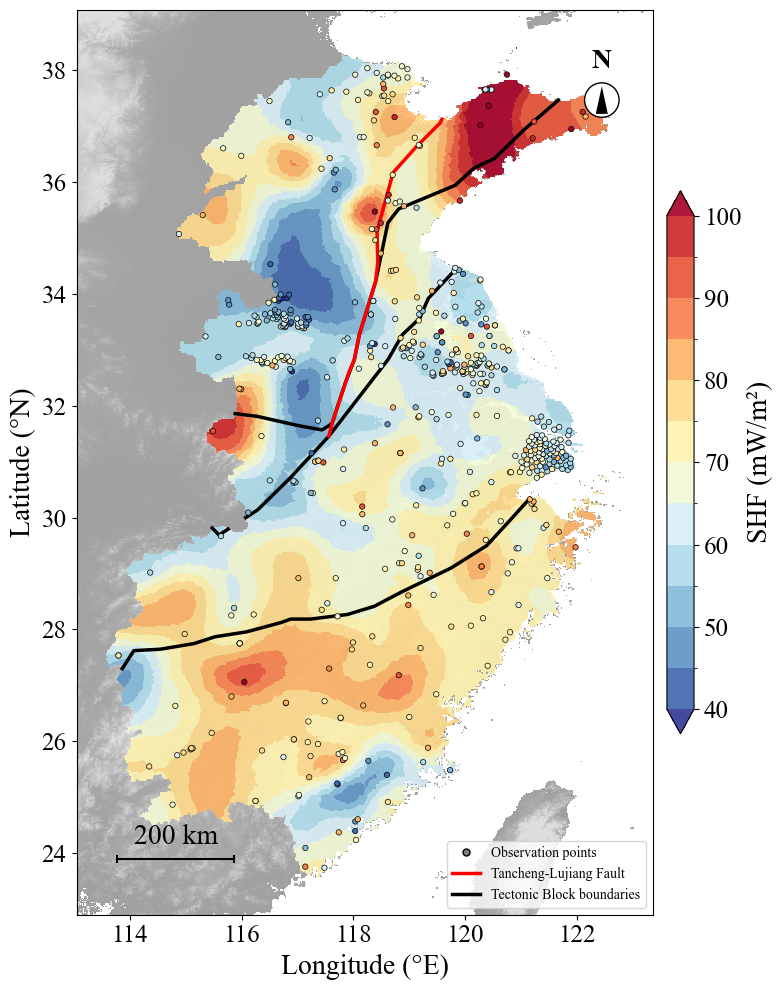

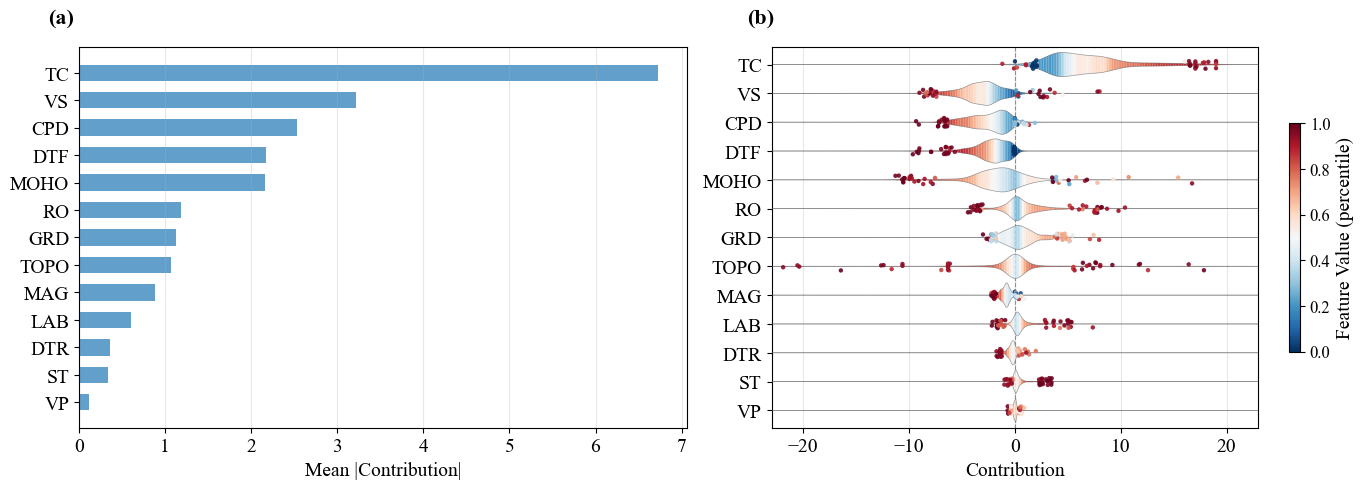

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x

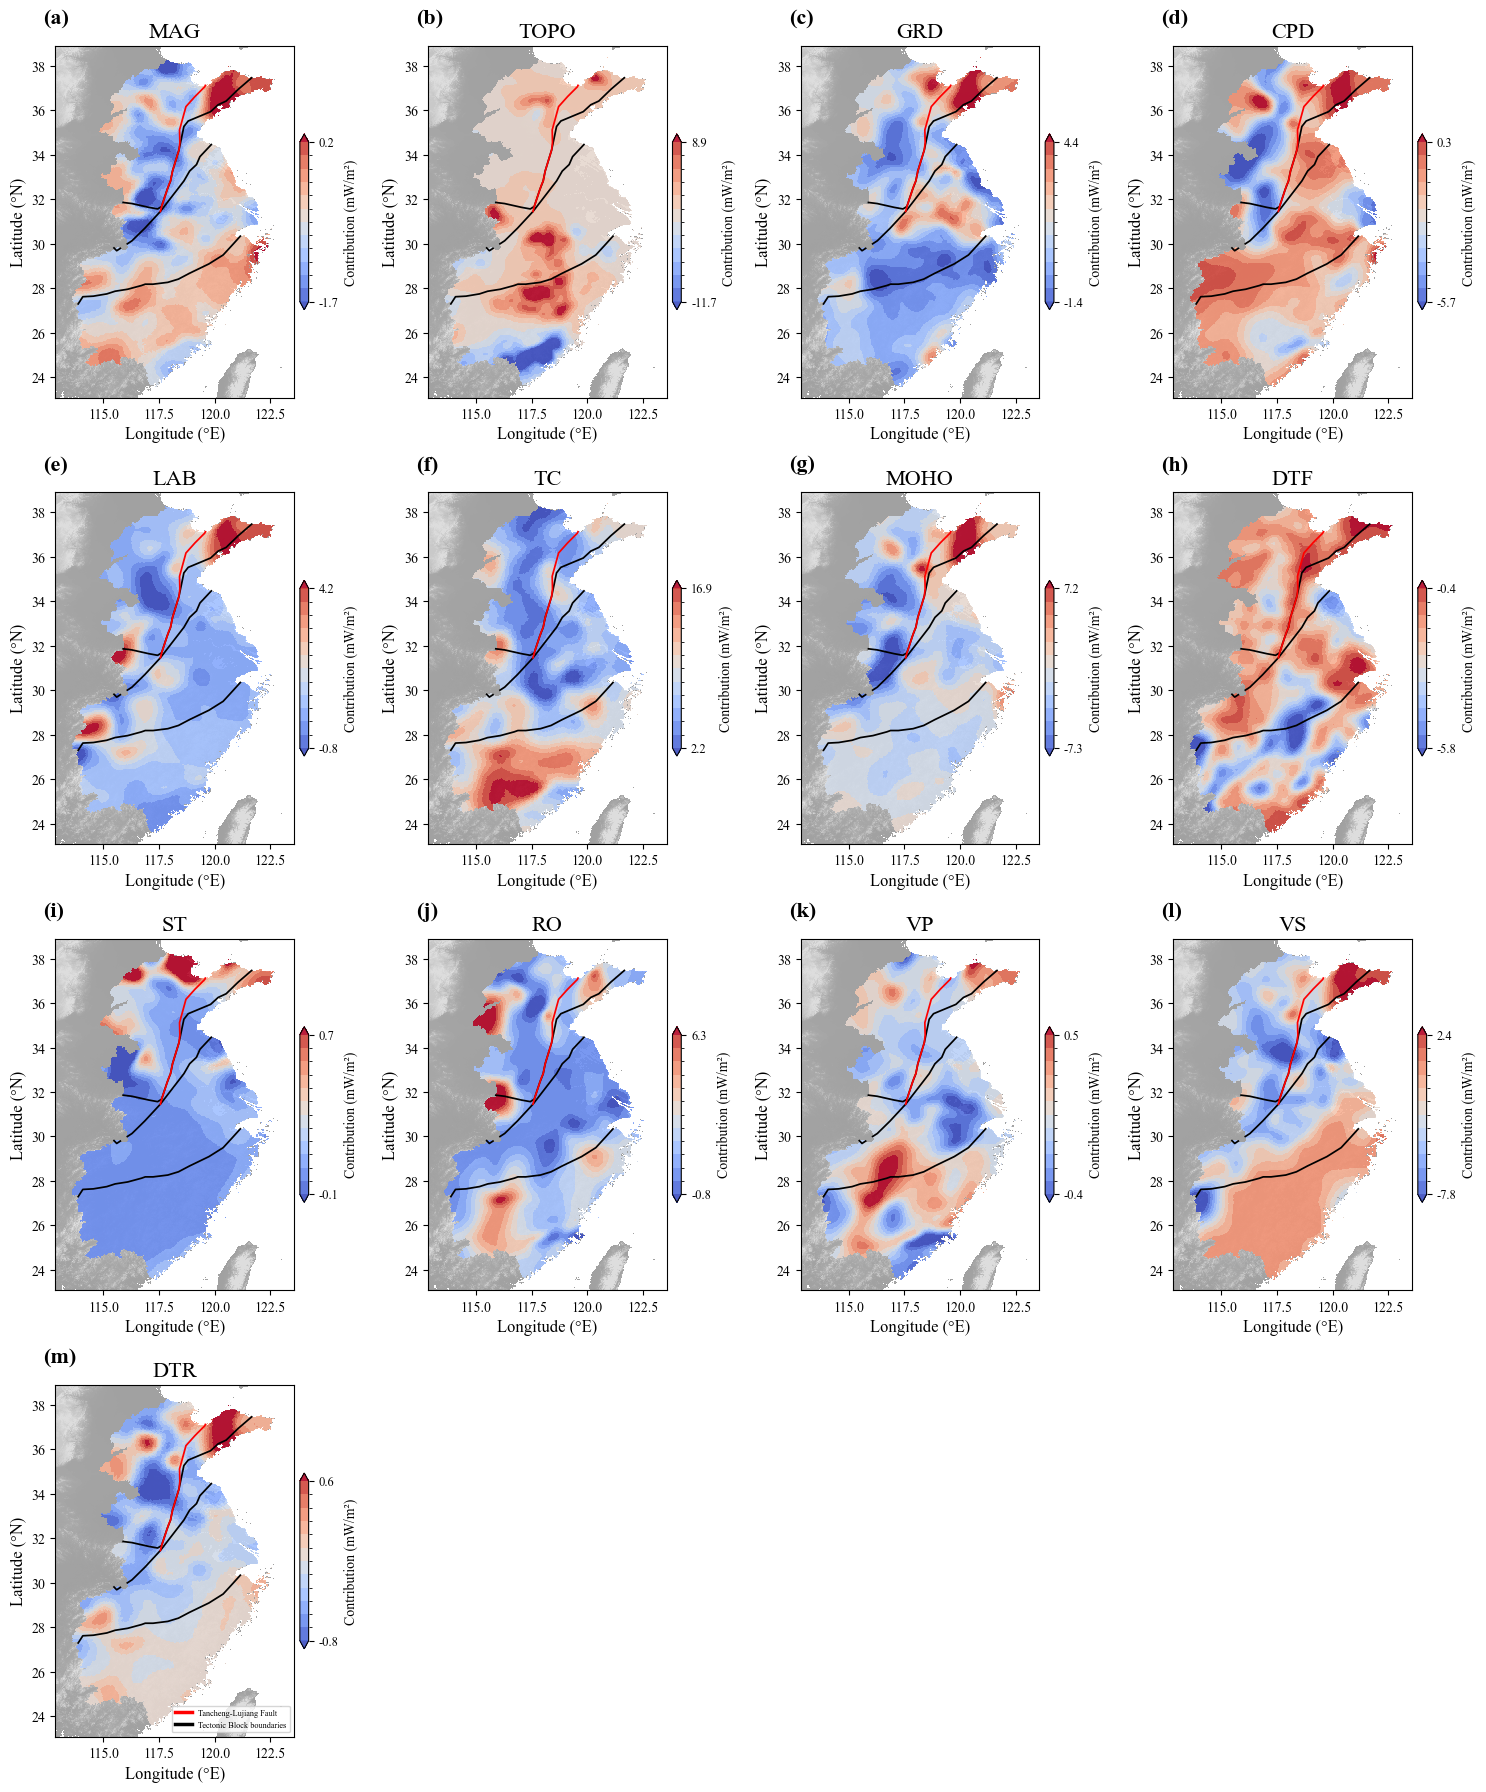

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


💾 已保存6个子图栅格数据: c:\KAN-OLS-SHF\output\train\rbfkan\combined_rasters


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


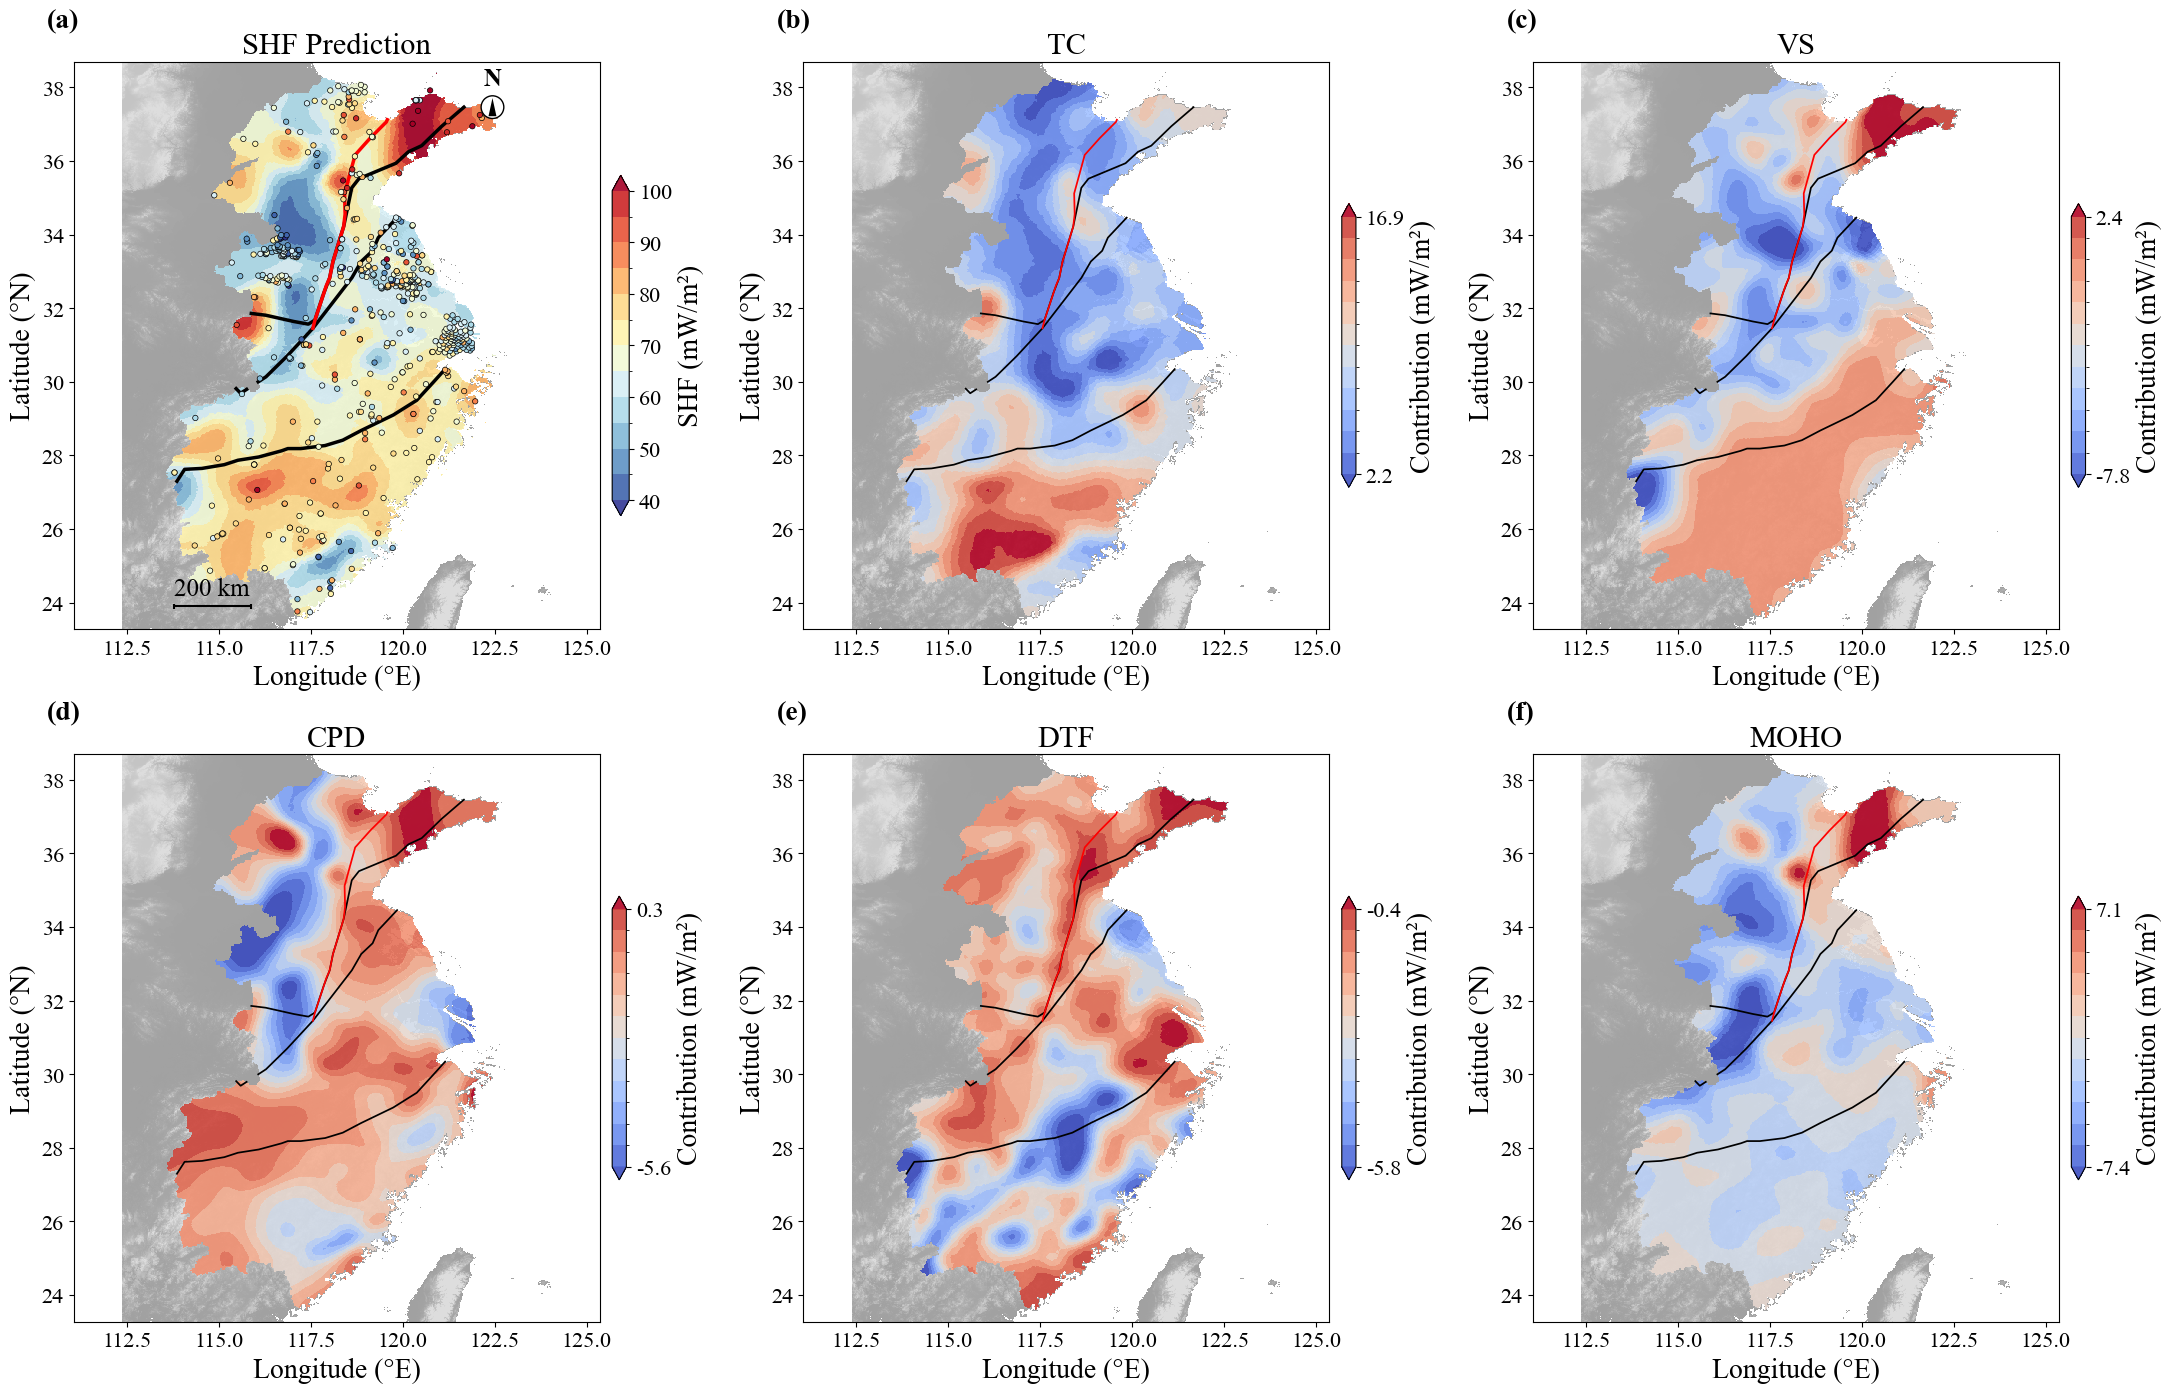

✅ RBFKAN done | Predicted 4131 points


In [4]:
# ---- Load this model's training data and prediction data (adaptive mesh) ----
df, X_dist_raw, X_geo_raw, y_raw = load_raw_data(r'c:\KAN-OLS-SHF\output\model\mesh\shf_with_distance_vectors.pkl')
pred_file = r'c:\KAN-OLS-SHF\output\model\mesh\geo_with_distance_vectors.pkl'
pred_df = pd.read_pickle(pred_file)
pred_dist_raw = np.array([np.array(s) if isinstance(s, (list, str)) else s for s in pred_df[DIST_COLS[0]]]).astype(np.float32)
if pred_dist_raw.ndim == 2 and pred_dist_raw.shape[1] == 1:
    pred_dist_raw = np.vstack(pred_dist_raw[:, 0]).astype(np.float32)
pred_geo_raw = pred_df[GEO_COLS].values.astype(np.float32)

# ==================== Cell E: RBFKAN prediction + spatial visualization (adaptive mesh + kriging) ====================
import os
import pyproj; pyproj.datadir.set_data_dir(r'C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj')
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.ops import unary_union
from scipy.interpolate import griddata as gd
from matplotlib.lines import Line2D
from matplotlib.colors import BoundaryNorm
try:
    from pykrige.ok import OrdinaryKriging
except ImportError:
    raise ImportError("pykrige 未安装，请先执行: pip install pykrige")

model_dir = r'c:\KAN-OLS-SHF\output\train\rbfkan'
shapefile = r'c:\KAN-OLS-SHF\data\eastChinaLine.shp'

# Keep the same feature count as GEO_COLS; short_names strictly aligned in order
n_feat = len(GEO_COLS)
short_names = [
    'MAG', 'TOPO', 'GRD', 'CPD', 'LAB', 'TC', 'MOHO', 'DTF',
    'ST', 'RO', 'VP', 'VS', 'DTR'
]
assert len(short_names) == n_feat, "short_names 数量与 GEO_COLS 不一致"
print(f"{'='*60}\n🔮 RBFKAN 空间预测与贡献度可视化（{n_feat} 个特征, Kriging）\n{'='*60}")

mask_polygon = None

def get_mask(shp):
    if not shp or not os.path.exists(shp):
        return None
    gdf = gpd.read_file(shp)
    if gdf.crs is not None and str(gdf.crs) != 'EPSG:4326':
        gdf = gdf.to_crs('EPSG:4326')
    ug = unary_union(gdf.geometry)
    if ug.geom_type in ('LineString', 'MultiLineString'):
        if ug.geom_type == 'LineString' and ug.is_ring:
            return Polygon(ug.coords)
        polys = [Polygon(l.coords) for l in (ug.geoms if ug.geom_type == 'MultiLineString' else [ug]) if l.is_ring]
        return unary_union(polys) if polys else None
    return ug if ug.geom_type in ('Polygon', 'MultiPolygon') else None

def get_ext(shp, df, pad=0.02):
    """Prefer the mask boundary so that the plotting extent fits the study area."""
    if mask_polygon is not None:
        xmn, ymn, xmx, ymx = mask_polygon.bounds
    else:
        xmn, xmx = df['Lon'].min(), df['Lon'].max()
        ymn, ymx = df['Lat'].min(), df['Lat'].max()
    xp = (xmx - xmn) * pad
    yp = (ymx - ymn) * pad
    return xmn - xp, xmx + xp, ymn - yp, ymx + yp

def plot_bdy(ax, shp, color='black', lw=1.5):
    if not os.path.exists(shp):
        return
    try:
        gdf = gpd.read_file(shp)
        if gdf.crs is not None and str(gdf.crs) != 'EPSG:4326':
            gdf = gdf.to_crs('EPSG:4326')
        for geom in gdf.geometry:
            if geom is None or geom.is_empty:
                continue
            g = geom.boundary if geom.geom_type in ('Polygon', 'MultiPolygon') else geom
            if g.geom_type == 'LineString':
                xs, ys = zip(*g.coords)
                ax.plot(xs, ys, color=color, lw=lw)
            elif g.geom_type == 'MultiLineString':
                for line in g.geoms:
                    xs, ys = zip(*line.coords)
                    ax.plot(xs, ys, color=color, lw=lw)
    except Exception:
        pass
def krige_interp(x_pts, y_pts, z_vals, xi, yi, mask_poly=None, n_closest=12,
                 variogram_model='spherical', variogram_parameters=None,
                 nlags=12, weight=True, project=True):
    """Kriging interpolation (project to a metric coordinate system + local neighborhood),
    making the result as close to ArcGIS as possible.

    Key improvements over the old version:
      1) First project lon/lat to an Azimuthal Equidistant projection centered on the data
         centroid (metric), avoiding using "degrees" as Euclidean distance, which distorts
         range/sill fitting (this is the biggest source of difference from ArcGIS);
      2) Increase the number of variogram lags (default nlags=12, close to the ArcGIS default),
         giving a more stable fit;
      3) variogram_parameters can be used to manually specify (nugget, sill, range);
         otherwise the variogram is fitted automatically;
      4) The default number of neighborhood points is n_closest=12 (close to the ArcGIS
         default search neighborhood of 12 points).
    """
    # ---- 1) Filter input points by the mask ----
    if mask_poly is not None:
        mask_pts = np.array([mask_poly.contains(Point(px, py)) for px, py in zip(x_pts, y_pts)])
        if mask_pts.sum() < 3:
            return np.full((len(yi), len(xi)), np.nan)
        x_f, y_f, z_f = x_pts[mask_pts], y_pts[mask_pts], z_vals[mask_pts]
    else:
        x_f, y_f, z_f = x_pts, y_pts, z_vals

    # ---- 2) Project to metric (Azimuthal Equidistant, centered on the data centroid) ----
    def _to_xy(lon, lat, lon0, lat0):
        try:
            import pyproj
            proj = pyproj.Proj(f'+proj=aeqd +lat_0={lat0:.6f} +lon_0={lon0:.6f} '
                               '+datum=WGS84 +units=m +no_defs')
            return proj(lon, lat)
        except Exception:
            # Fallback: equirectangular (Plate Carrée), referenced to the central latitude
            r = 6371000.0
            x = (np.asarray(lon, float) - lon0) * np.pi / 180.0 * r * np.cos(np.radians(lat0))
            y = (np.asarray(lat, float) - lat0) * np.pi / 180.0 * r
            return x, y

    if project:
        lon0 = float(np.median(x_f)); lat0 = float(np.median(y_f))
        xf_p, yf_p = _to_xy(x_f, y_f, lon0, lat0)
        xi_p, yi_p = _to_xy(xi, yi, lon0, lat0)
    else:
        xf_p, yf_p, xi_p, yi_p = x_f, y_f, xi, yi

    # ---- 3) Kriging (auto-fit variogram parameters; fall back to linear on failure) ----
    k = max(4, min(n_closest, len(xf_p)))
    ok_kwargs = dict(variogram_model=variogram_model, verbose=False,
                     enable_plotting=False, nlags=nlags, weight=weight)
    if variogram_parameters is not None:
        ok_kwargs['variogram_parameters'] = variogram_parameters
    try:
        OK = OrdinaryKriging(xf_p, yf_p, z_f, **ok_kwargs)
        Zg, _ = OK.execute('grid', xi_p, yi_p, n_closest_points=k, backend='loop')
        return np.ma.getdata(Zg)  # pykrige 1.7+ returns a plain ndarray; .data is a memoryview (cannot be slice-assigned)
    except Exception as e:
        print(f"  Kriging failed ({e})，回退 linear 模型")
        try:
            OK = OrdinaryKriging(xf_p, yf_p, z_f, variogram_model='linear',
                                 verbose=False, enable_plotting=False)
            Zg, _ = OK.execute('grid', xi_p, yi_p, n_closest_points=k, backend='loop')
            return np.ma.getdata(Zg)
        except Exception as e2:
            print(f"  Kriging fallback also failed: {e2}")
            return np.full((len(yi), len(xi)), np.nan)
# Replace the old L1/L2/L1_deduced with new tectonic lines, clipped to mask_polygon
plate_boundaries_paths = {
    'TLF': r'c:\KAN-OLS-SHF\tectonicPlate\TLF.shp',
    'TB': r'c:\KAN-OLS-SHF\tectonicPlate\TB.shp',
}

def plot_tectonic_bdy(ax, scale=1.0):
    """Draw and clip the new tectonic lines: TB, TLF."""
    xlim_saved = ax.get_xlim()
    ylim_saved = ax.get_ylim()
    configs = [
        ('TB',   'black', 2.5 * scale, '-'),
        ('TLF',  'red', 2.5 * scale, '-'),
    ]
    for key, color, lw, ls in configs:
        path = plate_boundaries_paths.get(key)
        if not path or not os.path.exists(path):
            continue
        try:
            gdf = gpd.read_file(path)
            if gdf.crs is not None and str(gdf.crs) != 'EPSG:4326':
                gdf = gdf.to_crs('EPSG:4326')
            for geom in gdf.geometry:
                if geom is None or geom.is_empty:
                    continue
                g = geom.boundary if geom.geom_type in ('Polygon', 'MultiPolygon') else geom
                lines = ([g] if g.geom_type == 'LineString'
                         else list(g.geoms) if g.geom_type == 'MultiLineString'
                         else [])
                for line in lines:
                    if mask_polygon is not None:
                        clipped = line.intersection(mask_polygon)
                        if clipped.is_empty:
                            continue
                        parts = [clipped] if clipped.geom_type == 'LineString' else \
                                (list(clipped.geoms) if clipped.geom_type == 'MultiLineString' else [])
                        for part in parts:
                            if part.geom_type == 'LineString':
                                xs, ys = zip(*part.coords)
                                ax.plot(xs, ys, color=color, linewidth=lw, linestyle=ls)
                    else:
                        xs, ys = zip(*line.coords)
                        ax.plot(xs, ys, color=color, linewidth=lw, linestyle=ls)
        except Exception:
            pass
    ax.set_xlim(xlim_saved)
    ax.set_ylim(ylim_saved)

tectonic_legend_handles = [
    Line2D([0], [0], color='red', linewidth=2.5, label='Tancheng-Lujiang Fault'),
    Line2D([0], [0], color='black', linewidth=2.5, label='Tectonic Block boundaries'),
]

mask_poly = get_mask(shapefile)
mask_polygon = mask_poly
print(f"Mask: {'OK' if mask_poly else 'None (full rect)'}")

# Backward-compatible old variable names
get_extent = get_ext
griddata_interp = gd
plot_boundary = plot_bdy

# Load model artifacts
pca = joblib.load(os.path.join(model_dir, 'pca.pkl'))
sXd = joblib.load(os.path.join(model_dir, 'scaler_X_dist.pkl'))
sXg = joblib.load(os.path.join(model_dir, 'scaler_X_geo.pkl'))
sy  = joblib.load(os.path.join(model_dir, 'scaler_y.pkl'))
coeffs = np.load(os.path.join(model_dir, 'reg_coefficients.npz'))
b0v = float(coeffs['beta0'])
bv = np.array(coeffs['beta'], dtype=float).flatten()
cfg = json.load(open(os.path.join(model_dir, 'config.json')))

# Transform prediction data
Xdp = pca.transform(pred_dist_raw)
Xds = sXd.transform(Xdp)
Xgs = sXg.transform(pred_geo_raw)

# Predict
model = RBFKAN([Xds.shape[1], cfg['n_hidden'], cfg['n_hidden'], n_feat],
               num_rbf=cfg.get('num_rbf', 4)).to(device)
model.load_state_dict(torch.load(os.path.join(model_dir, 'best_val_model.pth'), map_location=device))
model.eval()
with torch.no_grad():
    w_pred = model(torch.tensor(Xds, dtype=torch.float32, device=device))
    yp_s = (torch.tensor(b0v, device=device)
            + torch.sum(w_pred * torch.tensor(bv, device=device) * torch.tensor(Xgs, device=device), dim=1)).cpu().numpy()
y_pred = sy.inverse_transform(yp_s.reshape(-1, 1)).flatten()
out_df = pred_df.copy()
out_df["predicted_heat_flow"] = y_pred

out_df[["Lon", "Lat", "predicted_heat_flow"]].to_csv(
    r"c:\KAN-OLS-SHF\output\train\rbfkan\point_predictions.csv",
    index=False
)

print("已保存预测点热流 CSV")
print(f"Predicted {len(y_pred)} points | SHF range: [{y_pred.min():.1f}, {y_pred.max():.1f}] mW/m²")

# Contribution decomposition
w_np = w_pred.cpu().numpy()
a = float(sy.inverse_transform(np.array([[1.0]]))[0, 0] - sy.inverse_transform(np.array([[0.0]]))[0, 0])
contrib = a * (w_np * bv[None, :] * Xgs)
# Contribution on training points (Contribution Summary is drawn using training points)
Xdp_tr = pca.transform(X_dist_raw)
Xds_tr = sXd.transform(Xdp_tr)
Xgs_tr = sXg.transform(X_geo_raw)
with torch.no_grad():
    _wtr = model(torch.tensor(Xds_tr, dtype=torch.float32, device=device))
contrib_tr = a * (_wtr.cpu().numpy() * bv[None, :] * Xgs_tr)
intercept = a * b0v + float(sy.inverse_transform(np.array([[0.0]]))[0, 0])
print(f"Intercept: {intercept:.2f} mW/m²")

# Coordinates & adaptive grid (prevent memory overflow on very large grids)
x, y = pred_df['Lon'].values, pred_df['Lat'].values
xmin, xmax, ymin, ymax = get_ext(shapefile, pred_df)
TARGET_GRID = 500
nx = max(1, min(int((xmax - xmin) / 0.02), TARGET_GRID))
ny = max(1, min(int((ymax - ymin) / 0.02), TARGET_GRID))
dx = (xmax - xmin) / nx
dy = (ymax - ymin) / ny
xi = np.arange(xmin, xmax + dx / 2, dx)
yi = np.arange(ymin, ymax + dy / 2, dy)
print(f"Grid: {len(xi)}×{len(yi)} pts, step={dx:.4f}°×{dy:.4f}°")
Xg_g, Yg_g = np.meshgrid(xi, yi)

def _masked_grid(mask_poly, Xg_g, Yg_g):
    if mask_poly is None:
        return None
    pts = np.column_stack((Xg_g.ravel(), Yg_g.ravel()))
    return np.array([mask_poly.contains(Point(px, py)) for px, py in pts]).reshape(Xg_g.shape)

inside_grid = _masked_grid(mask_poly, Xg_g, Yg_g)

# Training points that fall inside the study area
train_in = np.array([mask_poly.contains(Point(lon, lat)) for lon, lat in zip(df['Lon'], df['Lat'])]) if mask_poly else np.ones(len(df), dtype=bool)

# ==================== Gray-white terrain basemap (pygmt SRTM15+, optional, as map background) ====================
import os as _os
_env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
_os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
_os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                       _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                       _os.environ.get('PATH', ''))
_tmpdir = r'C:\Users\19023\AppData\Local\Temp'
_os.makedirs(_tmpdir, exist_ok=True)
for _k in ('TMPDIR', 'TEMP', 'TMP'):
    _os.environ[_k] = _tmpdir
import matplotlib.colors as _mcolors

class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # pure white below sea level
        if np.any(land):
            out[land] = self.gray_lo + np.clip(v[land] / self.vland, 0.0, 1.0) * (self.gray_hi - self.gray_lo)
        return out

_gray_norm = GrayTerrainNorm()
import socket as _socket
_proxy_host, _proxy_port = '127.0.0.1', 7890
_sock = _socket.socket(_socket.AF_INET, _socket.SOCK_STREAM)
_sock.settimeout(0.3)
try:
    _sock.connect((_proxy_host, _proxy_port))
    _proxy_ok = True
except OSError:
    _proxy_ok = False
finally:
    _sock.close()
if _proxy_ok:
    _proxy_url = f'http://{_proxy_host}:{_proxy_port}'
    for _key in ('http_proxy', 'https_proxy', 'HTTP_PROXY', 'HTTPS_PROXY', 'GMT_HTTP_PROXY'):
        os.environ[_key] = _proxy_url
else:
    print('[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器')
_t_lon = _t_lat = _t_dem = None
try:
    import pygmt
    _region = [xmin - 1.0, xmax + 1.0, ymin - 0.5, ymax + 0.5]
    _relief = pygmt.datasets.load_earth_relief(resolution='15s', region=_region, registration=None)
    _step = 5
    _t_lon, _t_lat = np.meshgrid(_relief.lon.values[::_step], _relief.lat.values[::_step])
    _t_dem = _relief.values[::_step, ::_step].astype(float)
    print(f"灰白地形底图: {_t_dem.shape}")
except Exception as _e:
    print(f"地形加载失败，跳过地形底图: {_e}")
    _t_lon = _t_lat = _t_dem = None

def _draw_gray_terrain(ax):
    """Draw the gray-white terrain basemap on the current axes (bottom layer, zorder=0)."""
    if _t_dem is not None:
        ax.pcolormesh(_t_lon, _t_lat, _t_dem, cmap='Greys_r', norm=_gray_norm,
                      shading='auto', alpha=0.9, zorder=0)

# ---- Spatial Prediction Map (kriging interpolation) ----
shf_levels = np.arange(40, 105, 5)
norm_shf = BoundaryNorm(shf_levels, ncolors=256, extend='both')

Zg = krige_interp(x, y, y_pred, xi, yi, mask_poly)

# ---- After kriging, upsample to higher resolution via bilinear interpolation (prediction raster) ----
from scipy.interpolate import RegularGridInterpolator
UPSAMPLE = 4  # subdivision factor: each coarse grid cell is split into UPSAMPLE×UPSAMPLE
# Align fine-grid nodes exactly with coarse-grid nodes (each coarse cell split into UPSAMPLE×UPSAMPLE)
xi_hi = np.linspace(xi[0], xi[-1], (len(xi) - 1) * UPSAMPLE + 1)
yi_hi = np.linspace(yi[0], yi[-1], (len(yi) - 1) * UPSAMPLE + 1)
Xg_hi, Yg_hi = np.meshgrid(xi_hi, yi_hi)
_rgi = RegularGridInterpolator((yi, xi), Zg, method='linear',
                               bounds_error=False, fill_value=np.nan)
Zg_hi = _rgi((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape)
if inside_grid is not None:
    # Upsample the mask bilinearly as well, then clip outside the study area with a 0.5 threshold (avoid slow per-point contains)
    _rgi_mask = RegularGridInterpolator((yi, xi), inside_grid.astype(float),
                                        method='linear', bounds_error=False, fill_value=0.0)
    _in_hi = _rgi_mask((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape) >= 0.5
    Zg_hi[~_in_hi] = np.nan
print(f"  Upsampled prediction grid: {len(xi_hi)}×{len(yi_hi)} pts (bilinear x{UPSAMPLE})")

fig, ax = plt.subplots(figsize=(8, 10))
_draw_gray_terrain(ax)   # gray-white terrain basemap (background)
mesh = ax.pcolormesh(Xg_hi, Yg_hi, Zg_hi, cmap='RdYlBu_r', norm=norm_shf, shading='auto', alpha=0.9, zorder=1)
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('SHF (mW/m²)', fontsize=20)
cbar.ax.tick_params(labelsize=18)
ax.scatter(df.loc[train_in, 'Lon'].values, df.loc[train_in, 'Lat'].values,
           c=y_raw[train_in], cmap='RdYlBu_r', norm=norm_shf, s=15, ec='k', lw=0.5, zorder=5)
ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
plot_bdy(ax, shapefile, 'none', 1.2)
plot_tectonic_bdy(ax)
ax.axis('equal')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.tick_params(labelsize=18)
obs_handle = Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                    markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_handle] + tectonic_legend_handles, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, 200, fontsize=20)
add_north_arrow(ax, 0.02, 20)
plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'spatial_prediction.png'), dpi=800, bbox_inches='tight')
plt.show()

# ---- Contribution Summary ----
from scipy.stats import gaussian_kde, rankdata
from scipy.spatial import cKDTree
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize

ma = np.mean(np.abs(contrib_tr), axis=0)
idx = np.argsort(ma)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for _k, _ax in enumerate(axes):
    _ax.text(-0.05, 1.05, f'({chr(97+_k)})', transform=_ax.transAxes,
             fontsize=16, fontweight='bold', va='bottom', ha='left', clip_on=False)

# ---------- Left: Mean |Contribution| ----------
axes[0].barh(range(n_feat), ma[idx], color='#1f77b4', alpha=0.7, height=0.6)
axes[0].set_yticks(range(n_feat))
axes[0].set_yticklabels([short_names[i] for i in idx])
axes[0].invert_yaxis()
axes[0].tick_params(labelsize=14)
axes[0].grid(axis='x', alpha=0.3)
axes[0].set_xlabel('Mean |Contribution|', fontsize=14)

# ---------- Right: 小提琴（对称）+ 分箱热图内部着色 + 离群点着色 ----------
sorted_cc = contrib_tr[:, idx]
sorted_xg = Xgs_tr[:, idx]

all_cc = sorted_cc.flatten()
max_abs = max(np.abs(all_cc.min()), np.abs(all_cc.max())) * 1.05
cc_min, cc_max = -max_abs, max_abs
x_grid = np.linspace(cc_min, cc_max, 300)

step         = 1.0      # 特征之间间距
violin_half  = 0.42     # 小提琴半高（相对于 step）
cmap         = plt.cm.RdBu_r
norm_c       = Normalize(0.0, 1.0, clip=True)     # 色带刻度 0–1

for j in range(n_feat):
    y0   = (n_feat - 1 - j) * step
    cc_j = sorted_cc[:, j]
    xg_pct_j = (rankdata(sorted_xg[:, j]) - 1) / (len(sorted_xg) - 1)

    # KDE 密度
    try:
        kde = gaussian_kde(cc_j)
    except np.linalg.LinAlgError:
        continue
    dens = kde(x_grid)
    dens = dens / dens.max() * violin_half           # ★ 半高

    # 局部特征值：kNN，窄窗口，颜色随 x 变化明显
    k = max(20, len(cc_j) // 12)
    tree = cKDTree(cc_j.reshape(-1, 1))
    _, inds = tree.query(x_grid.reshape(-1, 1), k=k)
    local_feat = xg_pct_j[inds].mean(axis=1)
    if len(local_feat) > 5:
        local_feat = np.convolve(local_feat, np.ones(5) / 5, mode='same')

    # ★ 逐段构造对称多边形 —— 真正的小提琴形状
    verts, colors_seg = [], []
    for i in range(len(x_grid) - 1):
        h0, h1 = dens[i], dens[i + 1]
        if h0 < 1e-5 and h1 < 1e-5:
            continue
        verts.append([
            (x_grid[i],   y0 - h0),   # 下边
            (x_grid[i+1], y0 - h1),
            (x_grid[i+1], y0 + h1),   # 上边
            (x_grid[i],   y0 + h0),
        ])
        colors_seg.append(local_feat[i])

    if verts:
        coll = PolyCollection(verts, cmap=cmap, norm=norm_c,
                              edgecolors='none', zorder=2 + j * 1e-3)
        coll.set_array(np.array(colors_seg))
        axes[1].add_collection(coll)

    # 小提琴轮廓线
    axes[1].plot(x_grid, y0 + dens, color='0.35', lw=0.5, alpha=0.6,
                 zorder=2.5 + j * 1e-3)
    axes[1].plot(x_grid, y0 - dens, color='0.35', lw=0.5, alpha=0.6,
                 zorder=2.5 + j * 1e-3)

    # ★ 离群点：2.5–97.5 分位之外，直接按特征值着色
    lo, hi = np.percentile(cc_j, [2.5, 97.5])
    out_mask = (cc_j < lo) | (cc_j > hi)
    if out_mask.sum() > 0:
        y_jit = np.random.uniform(-violin_half * 0.35,
                                   violin_half * 0.35, out_mask.sum())
        axes[1].scatter(cc_j[out_mask], y0 + y_jit,
                        c=xg_pct_j[out_mask], cmap=cmap, norm=norm_c,
                        s=10, alpha=0.9, edgecolors='none',
                        zorder=3 + j * 1e-3)

# 装饰
axes[1].axvline(0, color='gray', ls='--', lw=0.8, zorder=0.9)
axes[1].set_yticks([(n_feat - 1 - j) * step for j in range(n_feat)])
axes[1].set_yticklabels([short_names[i] for i in idx])
axes[1].set_xlim(cc_min, cc_max)
axes[1].set_ylim(-0.6, (n_feat - 1) * step + 0.6)
axes[1].tick_params(labelsize=14)
axes[1].grid(axis='x', alpha=0.3)
axes[1].set_xlabel('Contribution', fontsize=14)

sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm_c)
cbar = plt.colorbar(sm, ax=axes[1], shrink=0.6)
cbar.set_label('Feature Value (percentile)', fontsize=14)
cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])   # 0–1 刻度
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'contribution_summary_violin_sym.png'),
            dpi=800, bbox_inches='tight')
plt.show()

# ---- Contribution Maps (dynamic layout) ----
ncols = 4
nrows = int(np.ceil(n_feat / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = np.array(axes).flatten()
for i, fn in enumerate(GEO_COLS):
    Zg_c = krige_interp(x, y, contrib[:, i], xi, yi, mask_poly)
    if inside_grid is not None:
        Zg_c[~inside_grid] = np.nan
    ax = axes[i]
    # Subplot label (top-left outside the axes)
    ax.text(-0.05, 1.05, f'({chr(97+i)})', transform=ax.transAxes, fontsize=16, fontweight='bold', va='bottom', ha='left', clip_on=False)
    valid_c = Zg_c[~np.isnan(Zg_c)]
    if len(valid_c) > 0:
        vmin_c = np.percentile(valid_c, 2)
        vmax_c = np.percentile(valid_c, 98)
        if vmax_c - vmin_c < 1e-12:
            vmin_c, vmax_c = -1, 1
        levels_c = np.linspace(vmin_c, vmax_c, 13)
        norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    else:
        vmin_c, vmax_c = -1, 1
        levels_c = np.linspace(vmin_c, vmax_c, 13)
        norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    _draw_gray_terrain(ax)   # gray-white terrain basemap (background)
    mesh_c = ax.pcolormesh(Xg_g, Yg_g, Zg_c, cmap='coolwarm', norm=norm_c, shading='auto', alpha=0.9, zorder=1)
    cb = plt.colorbar(mesh_c, ax=ax, shrink=0.5, pad=0.02)
    cb.set_label('Contribution (mW/m²)', fontsize=10)
    cb.set_ticks([vmin_c, vmax_c])
    cb.set_ticklabels([f'{vmin_c:.1f}', f'{vmax_c:.1f}'])
    cb.ax.tick_params(labelsize=9)
    plot_bdy(ax, shapefile, 'none', 1.0)
    plot_tectonic_bdy(ax, scale=0.5)
    ax.axis('equal')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(short_names[i], fontsize=16)
    ax.set_xlabel('Longitude (°E)', fontsize=12)
    ax.set_ylabel('Latitude (°N)', fontsize=12)
    ax.tick_params(labelsize=10)

# Hide empty subplots beyond the feature count, and put the legend on the last visible subplot
for j in range(n_feat, len(axes)):
    axes[j].set_visible(False)
axes[n_feat - 1].legend(handles=tectonic_legend_handles, loc='lower right', fontsize=6, framealpha=0.8)
plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'contribution_maps.png'), dpi=800, bbox_inches='tight')
plt.show()

# ---- Combined figure: SHF prediction raster + top-5 contribution features (2 rows × 3 cols, enlarged fonts) ----
top5 = idx[:5]
fig, axes = plt.subplots(2, 3, figsize=(22, 14))
axes = np.array(axes).flatten()

# Save the raster data of the 6 subplots (for other code files to read and display)
_rast_dir = os.path.join(model_dir, 'combined_rasters')
os.makedirs(_rast_dir, exist_ok=True)
# (a) SHF prediction raster (fine grid)
pd.DataFrame({'Lon': Xg_hi.ravel(), 'Lat': Yg_hi.ravel(),
              'SHF_pred': Zg_hi.ravel()}).to_csv(
    os.path.join(_rast_dir, 'raster_a_shf.csv'), index=False)

# (a) Surface heat flow prediction raster (same fine grid / level shading as the Spatial Prediction Map)
ax0 = axes[0]
_draw_gray_terrain(ax0)   # gray-white terrain basemap (background)
mesh0 = ax0.pcolormesh(Xg_hi, Yg_hi, Zg_hi, cmap='RdYlBu_r', norm=norm_shf, shading='auto', alpha=0.9, zorder=1)
cb0 = plt.colorbar(mesh0, ax=ax0, shrink=0.6, pad=0.02)
cb0.set_label('SHF (mW/m²)', fontsize=20)
cb0.ax.tick_params(labelsize=16)
ax0.scatter(df.loc[train_in, 'Lon'].values, df.loc[train_in, 'Lat'].values,
            c=y_raw[train_in], cmap='RdYlBu_r', norm=norm_shf, s=15, ec='k', lw=0.5, zorder=5)
ax0.set_xlabel('Longitude (°E)', fontsize=20)
ax0.set_ylabel('Latitude (°N)', fontsize=20)
plot_bdy(ax0, shapefile, 'none', 1.2)
plot_tectonic_bdy(ax0)
ax0.axis('equal')
ax0.set_xlim(xmin, xmax)
ax0.set_ylim(ymin, ymax)
ax0.tick_params(labelsize=16)
ax0.set_title('SHF Prediction', fontsize=22)
add_scale_bar_line(ax0, 200, fontsize=18)
add_north_arrow(ax0, 0.02, 18)

# (b)-(f) Top-5 feature contribution maps (level shading, colorbar ends = 2/98 percentiles)
for j, k in enumerate(top5, start=1):
    ax = axes[j]
    Zg_c = krige_interp(x, y, contrib[:, k], xi, yi, mask_poly)
    if inside_grid is not None:
        Zg_c[~inside_grid] = np.nan
    # Bilinear interpolation onto the fine grid (same grid as the SHF raster)
    _rgi_c = RegularGridInterpolator((yi, xi), Zg_c, method='linear', bounds_error=False, fill_value=np.nan)
    Zg_c_hi = _rgi_c((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape)
    if inside_grid is not None:
        Zg_c_hi[~_in_hi] = np.nan
    # Save this feature's contribution raster (fine grid)
    pd.DataFrame({'Lon': Xg_hi.ravel(), 'Lat': Yg_hi.ravel(),
                  'Contribution': Zg_c_hi.ravel()}).to_csv(
        os.path.join(_rast_dir, f'raster_{chr(97+j)}_contrib_{short_names[k]}.csv'), index=False)
    valid_c = Zg_c_hi[~np.isnan(Zg_c_hi)]
    if len(valid_c) > 0:
        vmin_c = np.percentile(valid_c, 2)
        vmax_c = np.percentile(valid_c, 98)
        if vmax_c - vmin_c < 1e-12:
            vmin_c, vmax_c = -1, 1
    else:
        vmin_c, vmax_c = -1, 1
    levels_c = np.linspace(vmin_c, vmax_c, 13)
    norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    _draw_gray_terrain(ax)   # gray-white terrain basemap (background)
    mesh_c = ax.pcolormesh(Xg_hi, Yg_hi, Zg_c_hi, cmap='coolwarm', norm=norm_c, shading='auto', alpha=0.9, zorder=1)
    cb = plt.colorbar(mesh_c, ax=ax, shrink=0.5, pad=0.02)
    cb.set_label('Contribution (mW/m²)', fontsize=20)
    cb.set_ticks([vmin_c, vmax_c])
    cb.set_ticklabels([f'{vmin_c:.1f}', f'{vmax_c:.1f}'])
    cb.ax.tick_params(labelsize=16)
    plot_bdy(ax, shapefile, 'none', 1.0)
    plot_tectonic_bdy(ax, scale=0.5)
    ax.axis('equal')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(short_names[k], fontsize=22)
    ax.set_xlabel('Longitude (°E)', fontsize=20)
    ax.set_ylabel('Latitude (°N)', fontsize=20)
    ax.tick_params(labelsize=16)

print(f"💾 已保存6个子图栅格数据: {_rast_dir}")

# Subplot label (top-left outside)
for _k, _ax in enumerate(axes):
    _ax.text(-0.05, 1.05, f'({chr(97+_k)})', transform=_ax.transAxes, fontsize=20, fontweight='bold', va='bottom', ha='left', clip_on=False)

plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'prediction_contribution_combined.png'), dpi=800, bbox_inches='tight')
plt.show()

print(f"✅ RBFKAN done | Predicted {len(y_pred)} points")


数据列: ['数据编号', 'Lon', 'Lat', 'SHF__mW_m2_', 'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU', 'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'crsthk', 'sedthk-m', 'bd6', 'bd7', 'bd8', 'bd9', 'ro6', 'ro7', 'ro8', 'ro9', 'vp6', 'vp7', 'vp8', 'vp9', 'vs6', 'vs7', 'vs8', 'vs9', 'H(km)', 'DTF', 'DTR', 'distance_vector_to_grids']
🔮 RBFKAN 空间预测与贡献度可视化（13 个特征, Kriging）
Mask: OK
Predicted 4131 points | SHF range: [31.6, 139.5] mW/m²
Intercept: 66.67 mW/m²
Grid: 482×501 pts, step=0.0200°×0.0308°
[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器
灰白地形底图: (789, 559)
  Upsampled prediction grid: 1925×2001 pts (bilinear x4)


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


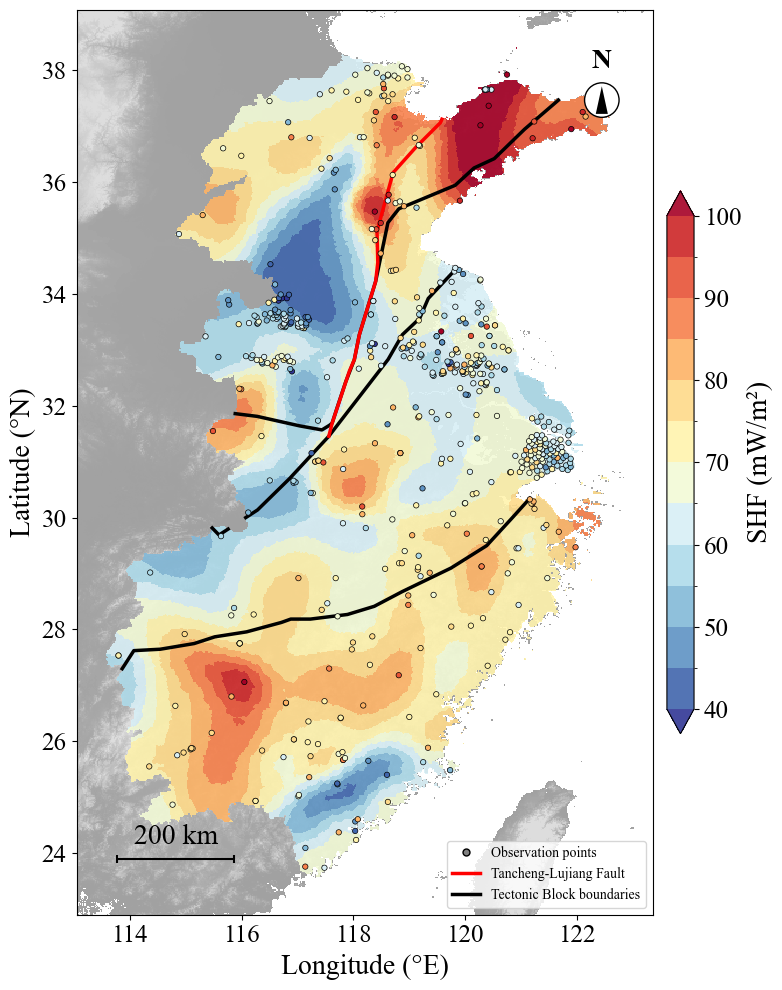

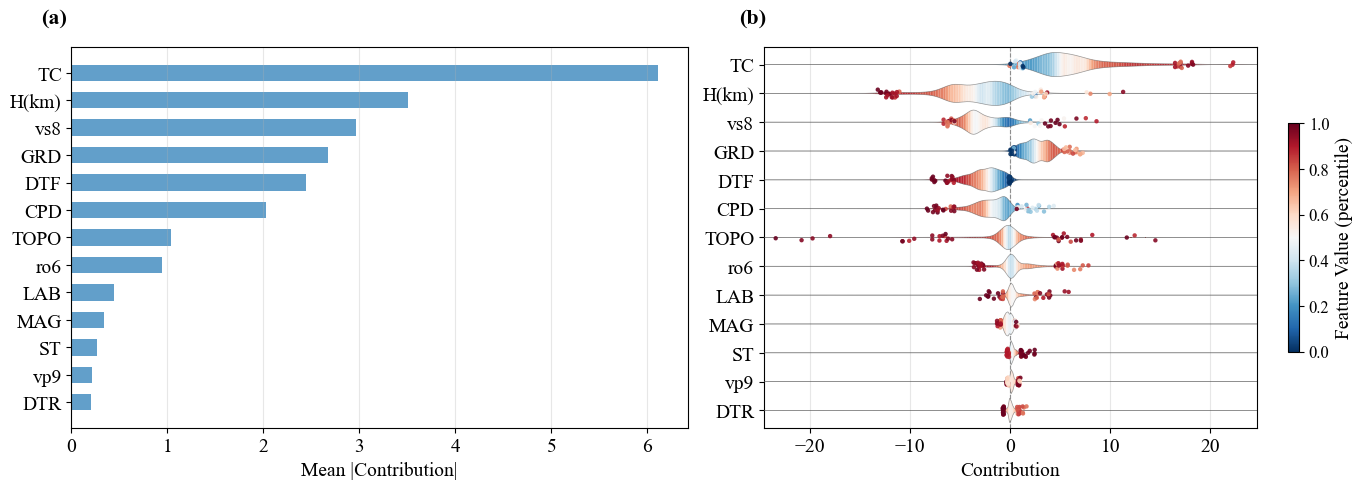

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x

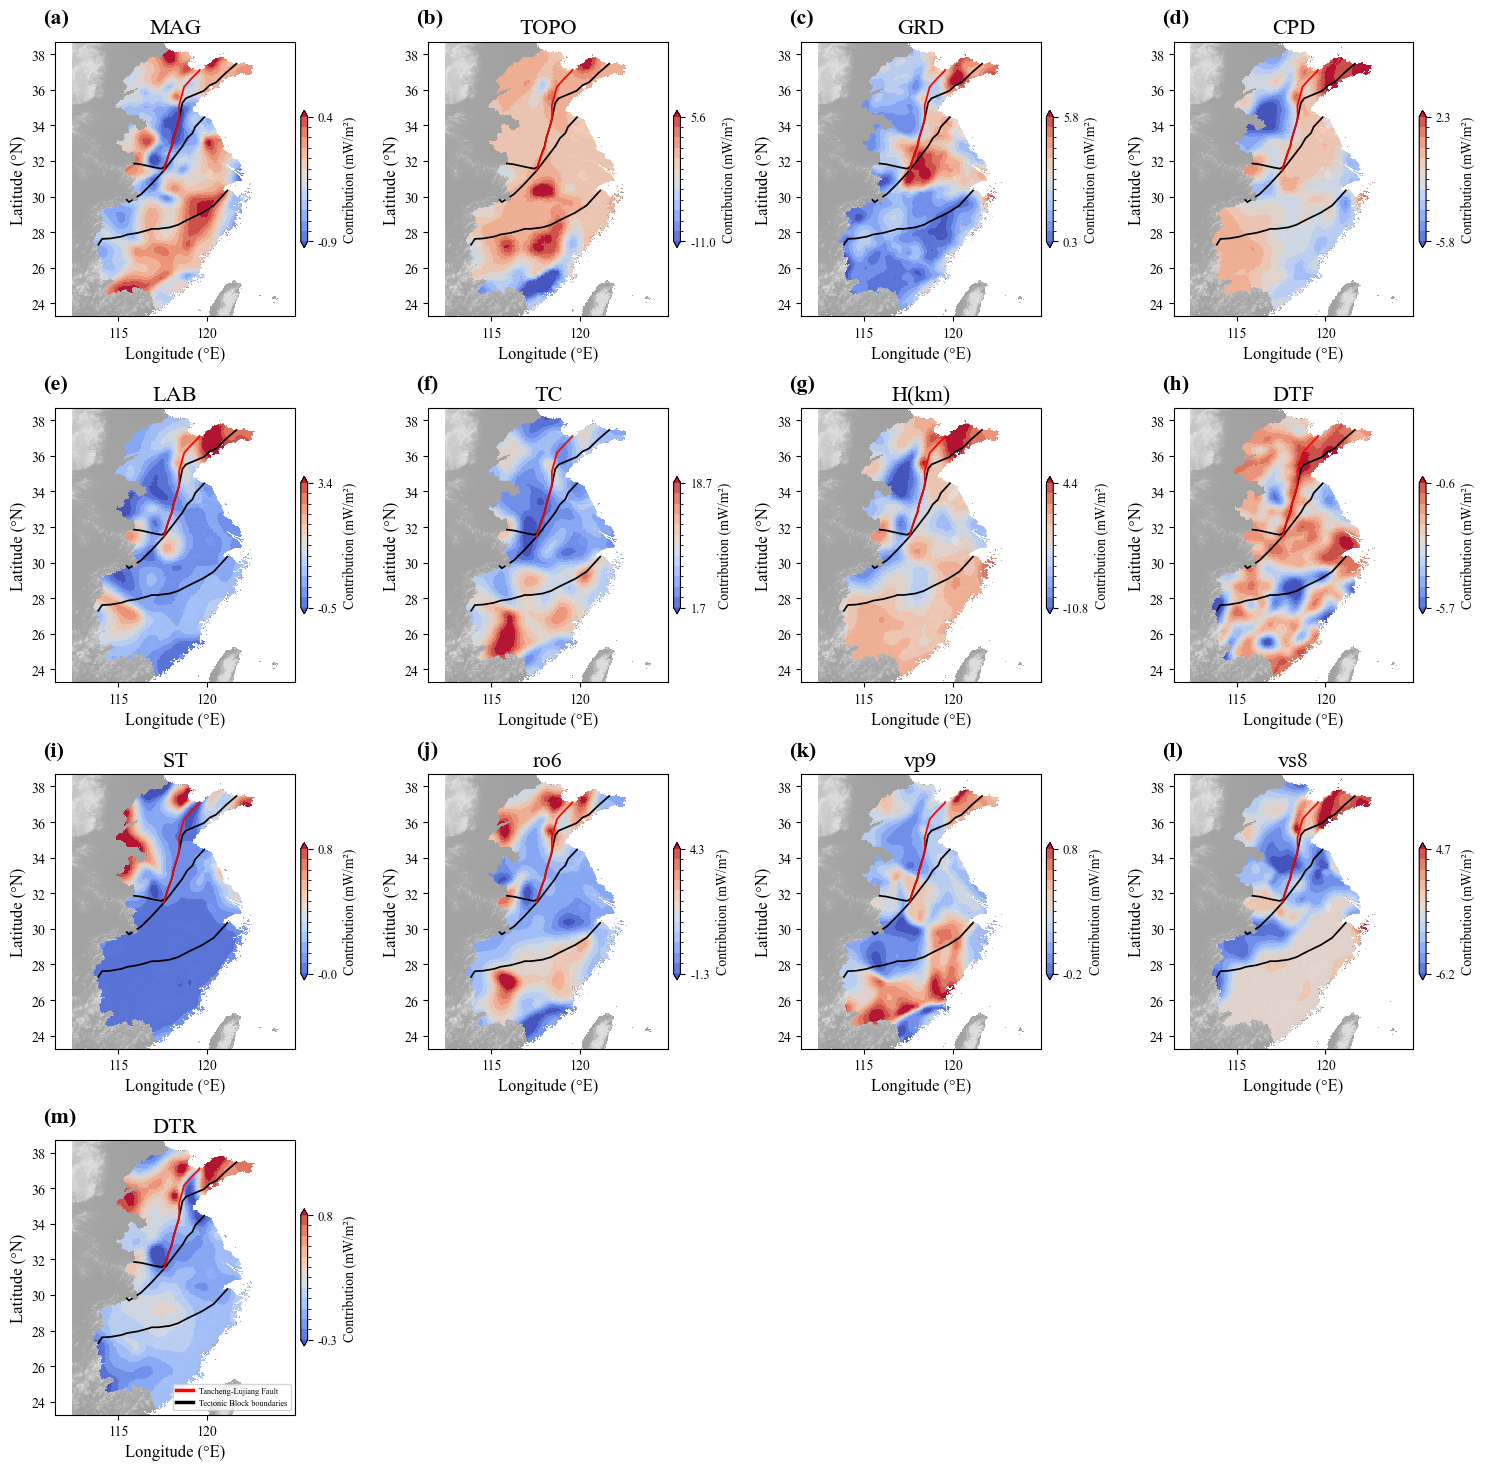

✅ RBFKAN done | Predicted 4131 points


In [5]:
# ---- Load this model's training data and prediction data (uniform mesh) ----
df, X_dist_raw, X_geo_raw, y_raw = load_raw_data(r'c:\KAN-OLS-SHF\output\model\mesh\shf_with_distance_vectors_normal.pkl')
pred_file = r'c:\KAN-OLS-SHF\output\model\mesh\geo_with_distance_vectors_normal.pkl'
pred_df = pd.read_pickle(pred_file)
pred_dist_raw = np.array([np.array(s) if isinstance(s, (list, str)) else s for s in pred_df[DIST_COLS[0]]]).astype(np.float32)
if pred_dist_raw.ndim == 2 and pred_dist_raw.shape[1] == 1:
    pred_dist_raw = np.vstack(pred_dist_raw[:, 0]).astype(np.float32)
pred_geo_raw = pred_df[GEO_COLS].values.astype(np.float32)

# ==================== Cell F: RBFKAN prediction + spatial visualization (uniform mesh + kriging) ====================
import os
import pyproj; pyproj.datadir.set_data_dir(r'C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj')
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.ops import unary_union
from scipy.interpolate import griddata as gd
from matplotlib.lines import Line2D
from matplotlib.colors import BoundaryNorm
try:
    from pykrige.ok import OrdinaryKriging
except ImportError:
    raise ImportError("pykrige 未安装，请先执行: pip install pykrige")

model_dir = r'c:\KAN-OLS-SHF\output\train\rbfkan_normal'
shapefile = r'c:\KAN-OLS-SHF\data\eastChinaLine.shp'

# Keep the same feature count as GEO_COLS; short_names strictly aligned in order
n_feat = len(GEO_COLS)
short_names = [
    'MAG', 'TOPO', 'GRD', 'CPD', 'LAB', 'TC', 'H(km)', 'DTF',
    'ST', 'ro6', 'vp9', 'vs8', 'DTR'
]
assert len(short_names) == n_feat, "short_names 数量与 GEO_COLS 不一致"
print(f"{'='*60}\n🔮 RBFKAN 空间预测与贡献度可视化（{n_feat} 个特征, Kriging）\n{'='*60}")

mask_polygon = None

def get_mask(shp):
    if not shp or not os.path.exists(shp):
        return None
    gdf = gpd.read_file(shp)
    if gdf.crs is not None and str(gdf.crs) != 'EPSG:4326':
        gdf = gdf.to_crs('EPSG:4326')
    ug = unary_union(gdf.geometry)
    if ug.geom_type in ('LineString', 'MultiLineString'):
        if ug.geom_type == 'LineString' and ug.is_ring:
            return Polygon(ug.coords)
        polys = [Polygon(l.coords) for l in (ug.geoms if ug.geom_type == 'MultiLineString' else [ug]) if l.is_ring]
        return unary_union(polys) if polys else None
    return ug if ug.geom_type in ('Polygon', 'MultiPolygon') else None

def get_ext(shp, df, pad=0.02):
    """Prefer the mask boundary so that the plotting extent fits the study area."""
    if mask_polygon is not None:
        xmn, ymn, xmx, ymx = mask_polygon.bounds
    else:
        xmn, xmx = df['Lon'].min(), df['Lon'].max()
        ymn, ymx = df['Lat'].min(), df['Lat'].max()
    xp = (xmx - xmn) * pad
    yp = (ymx - ymn) * pad
    return xmn - xp, xmx + xp, ymn - yp, ymx + yp

def plot_bdy(ax, shp, color='black', lw=1.5):
    if not os.path.exists(shp):
        return
    try:
        gdf = gpd.read_file(shp)
        if gdf.crs is not None and str(gdf.crs) != 'EPSG:4326':
            gdf = gdf.to_crs('EPSG:4326')
        for geom in gdf.geometry:
            if geom is None or geom.is_empty:
                continue
            g = geom.boundary if geom.geom_type in ('Polygon', 'MultiPolygon') else geom
            if g.geom_type == 'LineString':
                xs, ys = zip(*g.coords)
                ax.plot(xs, ys, color=color, lw=lw)
            elif g.geom_type == 'MultiLineString':
                for line in g.geoms:
                    xs, ys = zip(*line.coords)
                    ax.plot(xs, ys, color=color, lw=lw)
    except Exception:
        pass

def krige_interp(x_pts, y_pts, z_vals, xi, yi, mask_poly=None, n_closest=12,
                 variogram_model='spherical', variogram_parameters=None,
                 nlags=12, weight=True, project=True):
    """Kriging interpolation (project to a metric coordinate system + local neighborhood),
    making the result as close to ArcGIS as possible.

    Key improvements over the old version:
      1) First project lon/lat to an Azimuthal Equidistant projection centered on the data
         centroid (metric), avoiding using "degrees" as Euclidean distance, which distorts
         range/sill fitting (this is the biggest source of difference from ArcGIS);
      2) Increase the number of variogram lags (default nlags=12, close to the ArcGIS default),
         giving a more stable fit;
      3) variogram_parameters can be used to manually specify (nugget, sill, range);
         otherwise the variogram is fitted automatically;
      4) The default number of neighborhood points is n_closest=12 (close to the ArcGIS
         default search neighborhood of 12 points).
    """
    # ---- 1) Filter input points by the mask ----
    if mask_poly is not None:
        mask_pts = np.array([mask_poly.contains(Point(px, py)) for px, py in zip(x_pts, y_pts)])
        if mask_pts.sum() < 3:
            return np.full((len(yi), len(xi)), np.nan)
        x_f, y_f, z_f = x_pts[mask_pts], y_pts[mask_pts], z_vals[mask_pts]
    else:
        x_f, y_f, z_f = x_pts, y_pts, z_vals

    # ---- 2) Project to metric (Azimuthal Equidistant, centered on the data centroid) ----
    def _to_xy(lon, lat, lon0, lat0):
        try:
            import pyproj
            proj = pyproj.Proj(f'+proj=aeqd +lat_0={lat0:.6f} +lon_0={lon0:.6f} '
                               '+datum=WGS84 +units=m +no_defs')
            return proj(lon, lat)
        except Exception:
            # Fallback: equirectangular (Plate Carrée), referenced to the central latitude
            r = 6371000.0
            x = (np.asarray(lon, float) - lon0) * np.pi / 180.0 * r * np.cos(np.radians(lat0))
            y = (np.asarray(lat, float) - lat0) * np.pi / 180.0 * r
            return x, y

    if project:
        lon0 = float(np.median(x_f)); lat0 = float(np.median(y_f))
        xf_p, yf_p = _to_xy(x_f, y_f, lon0, lat0)
        xi_p, yi_p = _to_xy(xi, yi, lon0, lat0)
    else:
        xf_p, yf_p, xi_p, yi_p = x_f, y_f, xi, yi

    # ---- 3) Kriging (auto-fit variogram parameters; fall back to linear on failure) ----
    k = max(4, min(n_closest, len(xf_p)))
    ok_kwargs = dict(variogram_model=variogram_model, verbose=False,
                     enable_plotting=False, nlags=nlags, weight=weight)
    if variogram_parameters is not None:
        ok_kwargs['variogram_parameters'] = variogram_parameters
    try:
        OK = OrdinaryKriging(xf_p, yf_p, z_f, **ok_kwargs)
        Zg, _ = OK.execute('grid', xi_p, yi_p, n_closest_points=k, backend='loop')
        return np.ma.getdata(Zg)  # pykrige 1.7+ returns a plain ndarray; .data is a memoryview (cannot be slice-assigned)
    except Exception as e:
        print(f"  Kriging failed ({e})，回退 linear 模型")
        try:
            OK = OrdinaryKriging(xf_p, yf_p, z_f, variogram_model='linear',
                                 verbose=False, enable_plotting=False)
            Zg, _ = OK.execute('grid', xi_p, yi_p, n_closest_points=k, backend='loop')
            return np.ma.getdata(Zg)
        except Exception as e2:
            print(f"  Kriging fallback also failed: {e2}")
            return np.full((len(yi), len(xi)), np.nan)

# Replace the old L1/L2/L1_deduced with new tectonic lines, clipped to mask_polygon
plate_boundaries_paths = {
    'TLF': r'c:\KAN-OLS-SHF\tectonicPlate\TLF.shp',
    'TB': r'c:\KAN-OLS-SHF\tectonicPlate\TB.shp',
}

def plot_tectonic_bdy(ax, scale=1.0):
    """Draw and clip the new tectonic lines: TB, TLF."""
    xlim_saved = ax.get_xlim()
    ylim_saved = ax.get_ylim()
    configs = [
        ('TB',   'black', 2.5 * scale, '-'),
        ('TLF',  'red', 2.5 * scale, '-'),
    ]
    for key, color, lw, ls in configs:
        path = plate_boundaries_paths.get(key)
        if not path or not os.path.exists(path):
            continue
        try:
            gdf = gpd.read_file(path)
            if gdf.crs is not None and str(gdf.crs) != 'EPSG:4326':
                gdf = gdf.to_crs('EPSG:4326')
            for geom in gdf.geometry:
                if geom is None or geom.is_empty:
                    continue
                g = geom.boundary if geom.geom_type in ('Polygon', 'MultiPolygon') else geom
                lines = ([g] if g.geom_type == 'LineString'
                         else list(g.geoms) if g.geom_type == 'MultiLineString'
                         else [])
                for line in lines:
                    if mask_polygon is not None:
                        clipped = line.intersection(mask_polygon)
                        if clipped.is_empty:
                            continue
                        parts = [clipped] if clipped.geom_type == 'LineString' else \
                                (list(clipped.geoms) if clipped.geom_type == 'MultiLineString' else [])
                        for part in parts:
                            if part.geom_type == 'LineString':
                                xs, ys = zip(*part.coords)
                                ax.plot(xs, ys, color=color, linewidth=lw, linestyle=ls)
                    else:
                        xs, ys = zip(*line.coords)
                        ax.plot(xs, ys, color=color, linewidth=lw, linestyle=ls)
        except Exception:
            pass
    ax.set_xlim(xlim_saved)
    ax.set_ylim(ylim_saved)

tectonic_legend_handles = [
    Line2D([0], [0], color='red', linewidth=2.5, label='Tancheng-Lujiang Fault'),
    Line2D([0], [0], color='black', linewidth=2.5, label='Tectonic Block boundaries'),
]

mask_poly = get_mask(shapefile)
mask_polygon = mask_poly
print(f"Mask: {'OK' if mask_poly else 'None (full rect)'}")

# Backward-compatible old variable names
get_extent = get_ext
griddata_interp = gd
plot_boundary = plot_bdy

# Load model artifacts
pca = joblib.load(os.path.join(model_dir, 'pca.pkl'))
sXd = joblib.load(os.path.join(model_dir, 'scaler_X_dist.pkl'))
sXg = joblib.load(os.path.join(model_dir, 'scaler_X_geo.pkl'))
sy  = joblib.load(os.path.join(model_dir, 'scaler_y.pkl'))
coeffs = np.load(os.path.join(model_dir, 'reg_coefficients.npz'))
b0v = float(coeffs['beta0'])
bv = np.array(coeffs['beta'], dtype=float).flatten()
cfg = json.load(open(os.path.join(model_dir, 'config.json')))

# Transform prediction data
Xdp = pca.transform(pred_dist_raw)
Xds = sXd.transform(Xdp)
Xgs = sXg.transform(pred_geo_raw)

# Predict
model = RBFKAN([Xds.shape[1], cfg['n_hidden'], cfg['n_hidden'], n_feat],
               num_rbf=cfg.get('num_rbf', 4)).to(device)
model.load_state_dict(torch.load(os.path.join(model_dir, 'best_val_model.pth'), map_location=device))
model.eval()
with torch.no_grad():
    w_pred = model(torch.tensor(Xds, dtype=torch.float32, device=device))
    yp_s = (torch.tensor(b0v, device=device)
            + torch.sum(w_pred * torch.tensor(bv, device=device) * torch.tensor(Xgs, device=device), dim=1)).cpu().numpy()
y_pred = sy.inverse_transform(yp_s.reshape(-1, 1)).flatten()
print(f"Predicted {len(y_pred)} points | SHF range: [{y_pred.min():.1f}, {y_pred.max():.1f}] mW/m²")

# Contribution decomposition
w_np = w_pred.cpu().numpy()
a = float(sy.inverse_transform(np.array([[1.0]]))[0, 0] - sy.inverse_transform(np.array([[0.0]]))[0, 0])
contrib = a * (w_np * bv[None, :] * Xgs)
# Contribution on training points (Contribution Summary is drawn using training points)
Xdp_tr = pca.transform(X_dist_raw)
Xds_tr = sXd.transform(Xdp_tr)
Xgs_tr = sXg.transform(X_geo_raw)
with torch.no_grad():
    _wtr = model(torch.tensor(Xds_tr, dtype=torch.float32, device=device))
contrib_tr = a * (_wtr.cpu().numpy() * bv[None, :] * Xgs_tr)
intercept = a * b0v + float(sy.inverse_transform(np.array([[0.0]]))[0, 0])
print(f"Intercept: {intercept:.2f} mW/m²")

# Coordinates & adaptive grid (prevent memory overflow on very large grids)
x, y = pred_df['Lon'].values, pred_df['Lat'].values
xmin, xmax, ymin, ymax = get_ext(shapefile, pred_df)
TARGET_GRID = 500
nx = max(1, min(int((xmax - xmin) / 0.02), TARGET_GRID))
ny = max(1, min(int((ymax - ymin) / 0.02), TARGET_GRID))
dx = (xmax - xmin) / nx
dy = (ymax - ymin) / ny
xi = np.arange(xmin, xmax + dx / 2, dx)
yi = np.arange(ymin, ymax + dy / 2, dy)
print(f"Grid: {len(xi)}×{len(yi)} pts, step={dx:.4f}°×{dy:.4f}°")
Xg_g, Yg_g = np.meshgrid(xi, yi)

def _masked_grid(mask_poly, Xg_g, Yg_g):
    if mask_poly is None:
        return None
    pts = np.column_stack((Xg_g.ravel(), Yg_g.ravel()))
    return np.array([mask_poly.contains(Point(px, py)) for px, py in pts]).reshape(Xg_g.shape)

inside_grid = _masked_grid(mask_poly, Xg_g, Yg_g)

# Training points that fall inside the study area
train_in = np.array([mask_poly.contains(Point(lon, lat)) for lon, lat in zip(df['Lon'], df['Lat'])]) if mask_poly else np.ones(len(df), dtype=bool)

# ==================== Gray-white terrain basemap (pygmt SRTM15+, optional, as map background) ====================
import os as _os
_env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
_os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
_os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                       _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                       _os.environ.get('PATH', ''))
_tmpdir = r'C:\Users\19023\AppData\Local\Temp'
_os.makedirs(_tmpdir, exist_ok=True)
for _k in ('TMPDIR', 'TEMP', 'TMP'):
    _os.environ[_k] = _tmpdir
import matplotlib.colors as _mcolors

class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # pure white below sea level
        if np.any(land):
            out[land] = self.gray_lo + np.clip(v[land] / self.vland, 0.0, 1.0) * (self.gray_hi - self.gray_lo)
        return out

_gray_norm = GrayTerrainNorm()
import socket as _socket
_proxy_host, _proxy_port = '127.0.0.1', 7890
_sock = _socket.socket(_socket.AF_INET, _socket.SOCK_STREAM)
_sock.settimeout(0.3)
try:
    _sock.connect((_proxy_host, _proxy_port))
    _proxy_ok = True
except OSError:
    _proxy_ok = False
finally:
    _sock.close()
if _proxy_ok:
    _proxy_url = f'http://{_proxy_host}:{_proxy_port}'
    for _key in ('http_proxy', 'https_proxy', 'HTTP_PROXY', 'HTTPS_PROXY', 'GMT_HTTP_PROXY'):
        os.environ[_key] = _proxy_url
else:
    print('[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器')
_t_lon = _t_lat = _t_dem = None
try:
    import pygmt
    _region = [xmin - 1.0, xmax + 1.0, ymin - 0.5, ymax + 0.5]
    _relief = pygmt.datasets.load_earth_relief(resolution='15s', region=_region, registration=None)
    _step = 5
    _t_lon, _t_lat = np.meshgrid(_relief.lon.values[::_step], _relief.lat.values[::_step])
    _t_dem = _relief.values[::_step, ::_step].astype(float)
    print(f"灰白地形底图: {_t_dem.shape}")
except Exception as _e:
    print(f"地形加载失败，跳过地形底图: {_e}")
    _t_lon = _t_lat = _t_dem = None

def _draw_gray_terrain(ax):
    """Draw the gray-white terrain basemap on the current axes (bottom layer, zorder=0)."""
    if _t_dem is not None:
        ax.pcolormesh(_t_lon, _t_lat, _t_dem, cmap='Greys_r', norm=_gray_norm,
                      shading='auto', alpha=0.9, zorder=0)

# ---- Spatial Prediction Map (kriging interpolation) ----
shf_levels = np.arange(40, 105, 5)
norm_shf = BoundaryNorm(shf_levels, ncolors=256, extend='both')

Zg = krige_interp(x, y, y_pred, xi, yi, mask_poly)
# If kriging produces NaN (rare), fill with nearest neighbor first to avoid holes in upsampling
if np.isnan(Zg).any():
    from scipy import ndimage
    _idx = ndimage.distance_transform_edt(np.isnan(Zg), return_distances=False, return_indices=True)
    Zg = Zg[tuple(_idx)]

# ---- After kriging, upsample to higher resolution via bilinear interpolation (prediction raster) ----
from scipy.interpolate import RegularGridInterpolator
UPSAMPLE = 4  # subdivision factor: each coarse grid cell is split into UPSAMPLE×UPSAMPLE
# Align fine-grid nodes exactly with coarse-grid nodes (each coarse cell split into UPSAMPLE×UPSAMPLE)
xi_hi = np.linspace(xi[0], xi[-1], (len(xi) - 1) * UPSAMPLE + 1)
yi_hi = np.linspace(yi[0], yi[-1], (len(yi) - 1) * UPSAMPLE + 1)
Xg_hi, Yg_hi = np.meshgrid(xi_hi, yi_hi)
_rgi = RegularGridInterpolator((yi, xi), Zg, method='linear',
                               bounds_error=False, fill_value=np.nan)
Zg_hi = _rgi((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape)
if inside_grid is not None:
    # Upsample the mask bilinearly as well, then clip outside the study area with a 0.5 threshold (avoid slow per-point contains)
    _rgi_mask = RegularGridInterpolator((yi, xi), inside_grid.astype(float),
                                        method='linear', bounds_error=False, fill_value=0.0)
    _in_hi = _rgi_mask((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape) >= 0.5
    Zg_hi[~_in_hi] = np.nan
print(f"  Upsampled prediction grid: {len(xi_hi)}×{len(yi_hi)} pts (bilinear x{UPSAMPLE})")

fig, ax = plt.subplots(figsize=(8, 10))
_draw_gray_terrain(ax)   # gray-white terrain basemap (background)
mesh = ax.pcolormesh(Xg_hi, Yg_hi, Zg_hi, cmap='RdYlBu_r', norm=norm_shf, shading='auto', alpha=0.9, zorder=1)
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('SHF (mW/m²)', fontsize=20)
cbar.ax.tick_params(labelsize=18)
ax.scatter(df.loc[train_in, 'Lon'].values, df.loc[train_in, 'Lat'].values,
           c=y_raw[train_in], cmap='RdYlBu_r', norm=norm_shf, s=15, ec='k', lw=0.5, zorder=5)
ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
plot_bdy(ax, shapefile, 'none', 1.2)
plot_tectonic_bdy(ax)
ax.axis('equal')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.tick_params(labelsize=18)
obs_handle = Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                    markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_handle] + tectonic_legend_handles, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, 200, fontsize=20)
add_north_arrow(ax, 0.02, 20)
plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'spatial_prediction.png'), dpi=800, bbox_inches='tight')
plt.show()

# ---- Contribution Summary ----
from scipy.stats import gaussian_kde, rankdata
from scipy.spatial import cKDTree
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize

ma = np.mean(np.abs(contrib_tr), axis=0)
idx = np.argsort(ma)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for _k, _ax in enumerate(axes):
    _ax.text(-0.05, 1.05, f'({chr(97+_k)})', transform=_ax.transAxes,
             fontsize=16, fontweight='bold', va='bottom', ha='left', clip_on=False)

# ---------- Left: Mean |Contribution| ----------
axes[0].barh(range(n_feat), ma[idx], color='#1f77b4', alpha=0.7, height=0.6)
axes[0].set_yticks(range(n_feat))
axes[0].set_yticklabels([short_names[i] for i in idx])
axes[0].invert_yaxis()
axes[0].tick_params(labelsize=14)
axes[0].grid(axis='x', alpha=0.3)
axes[0].set_xlabel('Mean |Contribution|', fontsize=14)

# ---------- Right: 小提琴（对称）+ 分箱热图内部着色 + 离群点着色 ----------
sorted_cc = contrib_tr[:, idx]
sorted_xg = Xgs_tr[:, idx]

all_cc = sorted_cc.flatten()
max_abs = max(np.abs(all_cc.min()), np.abs(all_cc.max())) * 1.05
cc_min, cc_max = -max_abs, max_abs
x_grid = np.linspace(cc_min, cc_max, 300)

step         = 1.0      # 特征之间间距
violin_half  = 0.42     # 小提琴半高（相对于 step）
cmap         = plt.cm.RdBu_r
norm_c       = Normalize(0.0, 1.0, clip=True)     # 色带刻度 0–1

for j in range(n_feat):
    y0   = (n_feat - 1 - j) * step
    cc_j = sorted_cc[:, j]
    xg_pct_j = (rankdata(sorted_xg[:, j]) - 1) / (len(sorted_xg) - 1)

    # KDE 密度
    try:
        kde = gaussian_kde(cc_j)
    except np.linalg.LinAlgError:
        continue
    dens = kde(x_grid)
    dens = dens / dens.max() * violin_half           # ★ 半高

    # 局部特征值：kNN，窄窗口，颜色随 x 变化明显
    k = max(20, len(cc_j) // 12)
    tree = cKDTree(cc_j.reshape(-1, 1))
    _, inds = tree.query(x_grid.reshape(-1, 1), k=k)
    local_feat = xg_pct_j[inds].mean(axis=1)
    if len(local_feat) > 5:
        local_feat = np.convolve(local_feat, np.ones(5) / 5, mode='same')

    # ★ 逐段构造对称多边形 —— 真正的小提琴形状
    verts, colors_seg = [], []
    for i in range(len(x_grid) - 1):
        h0, h1 = dens[i], dens[i + 1]
        if h0 < 1e-5 and h1 < 1e-5:
            continue
        verts.append([
            (x_grid[i],   y0 - h0),   # 下边
            (x_grid[i+1], y0 - h1),
            (x_grid[i+1], y0 + h1),   # 上边
            (x_grid[i],   y0 + h0),
        ])
        colors_seg.append(local_feat[i])

    if verts:
        coll = PolyCollection(verts, cmap=cmap, norm=norm_c,
                              edgecolors='none', zorder=2 + j * 1e-3)
        coll.set_array(np.array(colors_seg))
        axes[1].add_collection(coll)

    # 小提琴轮廓线
    axes[1].plot(x_grid, y0 + dens, color='0.35', lw=0.5, alpha=0.6,
                 zorder=2.5 + j * 1e-3)
    axes[1].plot(x_grid, y0 - dens, color='0.35', lw=0.5, alpha=0.6,
                 zorder=2.5 + j * 1e-3)

    # ★ 离群点：2.5–97.5 分位之外，直接按特征值着色
    lo, hi = np.percentile(cc_j, [2.5, 97.5])
    out_mask = (cc_j < lo) | (cc_j > hi)
    if out_mask.sum() > 0:
        y_jit = np.random.uniform(-violin_half * 0.35,
                                   violin_half * 0.35, out_mask.sum())
        axes[1].scatter(cc_j[out_mask], y0 + y_jit,
                        c=xg_pct_j[out_mask], cmap=cmap, norm=norm_c,
                        s=10, alpha=0.9, edgecolors='none',
                        zorder=3 + j * 1e-3)

# 装饰
axes[1].axvline(0, color='gray', ls='--', lw=0.8, zorder=0.9)
axes[1].set_yticks([(n_feat - 1 - j) * step for j in range(n_feat)])
axes[1].set_yticklabels([short_names[i] for i in idx])
axes[1].set_xlim(cc_min, cc_max)
axes[1].set_ylim(-0.6, (n_feat - 1) * step + 0.6)
axes[1].tick_params(labelsize=14)
axes[1].grid(axis='x', alpha=0.3)
axes[1].set_xlabel('Contribution', fontsize=14)

sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm_c)
cbar = plt.colorbar(sm, ax=axes[1], shrink=0.6)
cbar.set_label('Feature Value (percentile)', fontsize=14)
cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])   # 0–1 刻度
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'contribution_summary_violin_sym.png'),
            dpi=800, bbox_inches='tight')
plt.show()

# ---- Contribution Maps (grid layout) ----
fig, axes = plt.subplots(5, 4, figsize=(15, 18))
axes = axes.flatten()
for i, fn in enumerate(GEO_COLS):
    Zg_c = krige_interp(x, y, contrib[:, i], xi, yi, mask_poly)
    if inside_grid is not None:
        Zg_c[~inside_grid] = np.nan
    ax = axes[i]
    # Subplot label (top-left outside the axes)
    ax.text(-0.05, 1.05, f'({chr(97+i)})', transform=ax.transAxes, fontsize=16, fontweight='bold', va='bottom', ha='left', clip_on=False)
    valid_c = Zg_c[~np.isnan(Zg_c)]
    if len(valid_c) > 0:
        vmin_c = np.percentile(valid_c, 2)
        vmax_c = np.percentile(valid_c, 98)
        if vmax_c - vmin_c < 1e-12:
            vmin_c, vmax_c = -1, 1
        levels_c = np.linspace(vmin_c, vmax_c, 13)
        norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    else:
        vmin_c, vmax_c = -1, 1
        levels_c = np.linspace(vmin_c, vmax_c, 13)
        norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    _draw_gray_terrain(ax)   # gray-white terrain basemap (background)
    mesh_c = ax.pcolormesh(Xg_g, Yg_g, Zg_c, cmap='coolwarm', norm=norm_c, shading='auto', alpha=0.9, zorder=1)
    cb = plt.colorbar(mesh_c, ax=ax, shrink=0.5, pad=0.02)
    cb.set_label('Contribution (mW/m²)', fontsize=10)
    cb.set_ticks([vmin_c, vmax_c])
    cb.set_ticklabels([f'{vmin_c:.1f}', f'{vmax_c:.1f}'])
    cb.ax.tick_params(labelsize=9)
    plot_bdy(ax, shapefile, 'none', 1.0)
    plot_tectonic_bdy(ax, scale=0.5)
    ax.axis('equal')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(short_names[i], fontsize=16)
    ax.set_xlabel('Longitude (°E)', fontsize=12)
    ax.set_ylabel('Latitude (°N)', fontsize=12)
    ax.tick_params(labelsize=10)

# Hide empty subplots beyond the feature count, and put the legend on the last visible subplot
for j in range(n_feat, len(axes)):
    axes[j].set_visible(False)
axes[n_feat - 1].legend(handles=tectonic_legend_handles, loc='lower right', fontsize=6, framealpha=0.8)
plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'contribution_maps.png'), dpi=800, bbox_inches='tight')
plt.show()

print(f"✅ RBFKAN done | Predicted {len(y_pred)} points")


数据列: ['数据编号', 'Lon', 'Lat', 'SHF__mW_m2_', 'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU', 'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'crsthk', 'sedthk-m', 'bd6', 'bd7', 'bd8', 'bd9', 'ro6', 'ro7', 'ro8', 'ro9', 'vp6', 'vp7', 'vp8', 'vp9', 'vs6', 'vs7', 'vs8', 'vs9', 'H(km)', 'DTF', 'DTR', 'distance_vector_to_grids']
🔮 BSRBF_KAN 空间预测与贡献度可视化
Predicted 4131 points | SHF range: [38.0, 133.7] mW/m²
Grid: 482×501 pts, step=0.0200°×0.0308°
[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器
灰白地形底图: (789, 559)
  Upsampled prediction grid: 1925×2001 pts (bilinear x4)


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


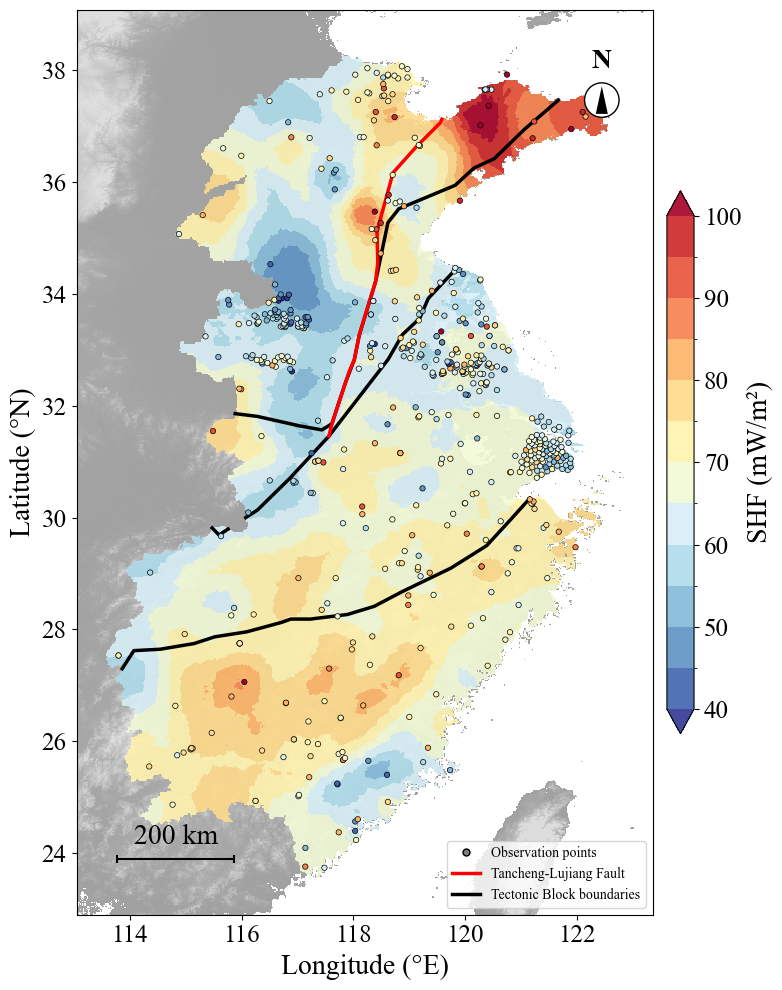

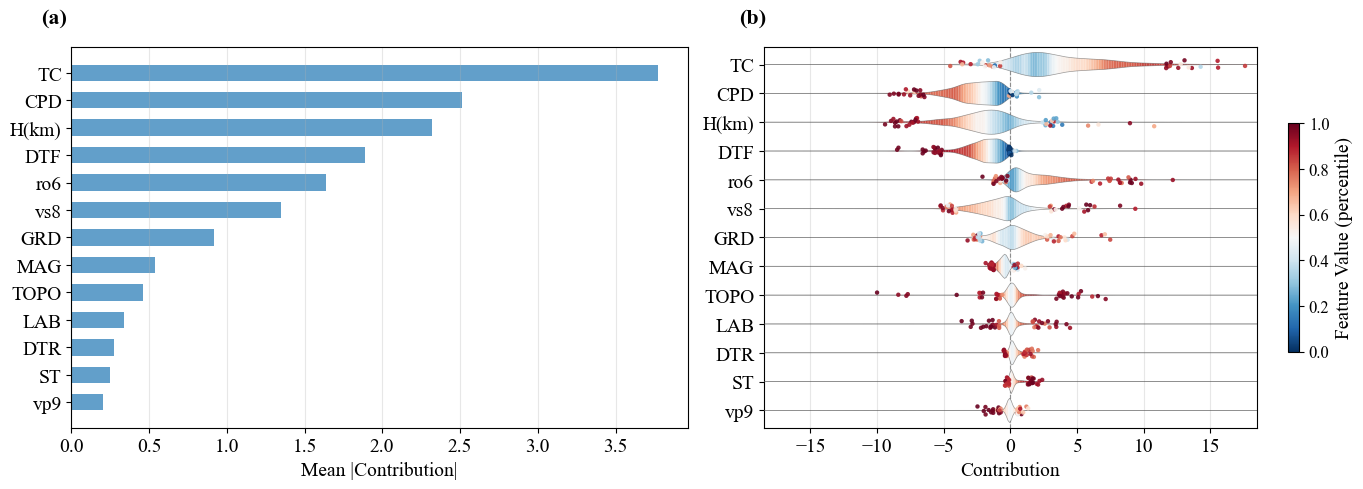

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x

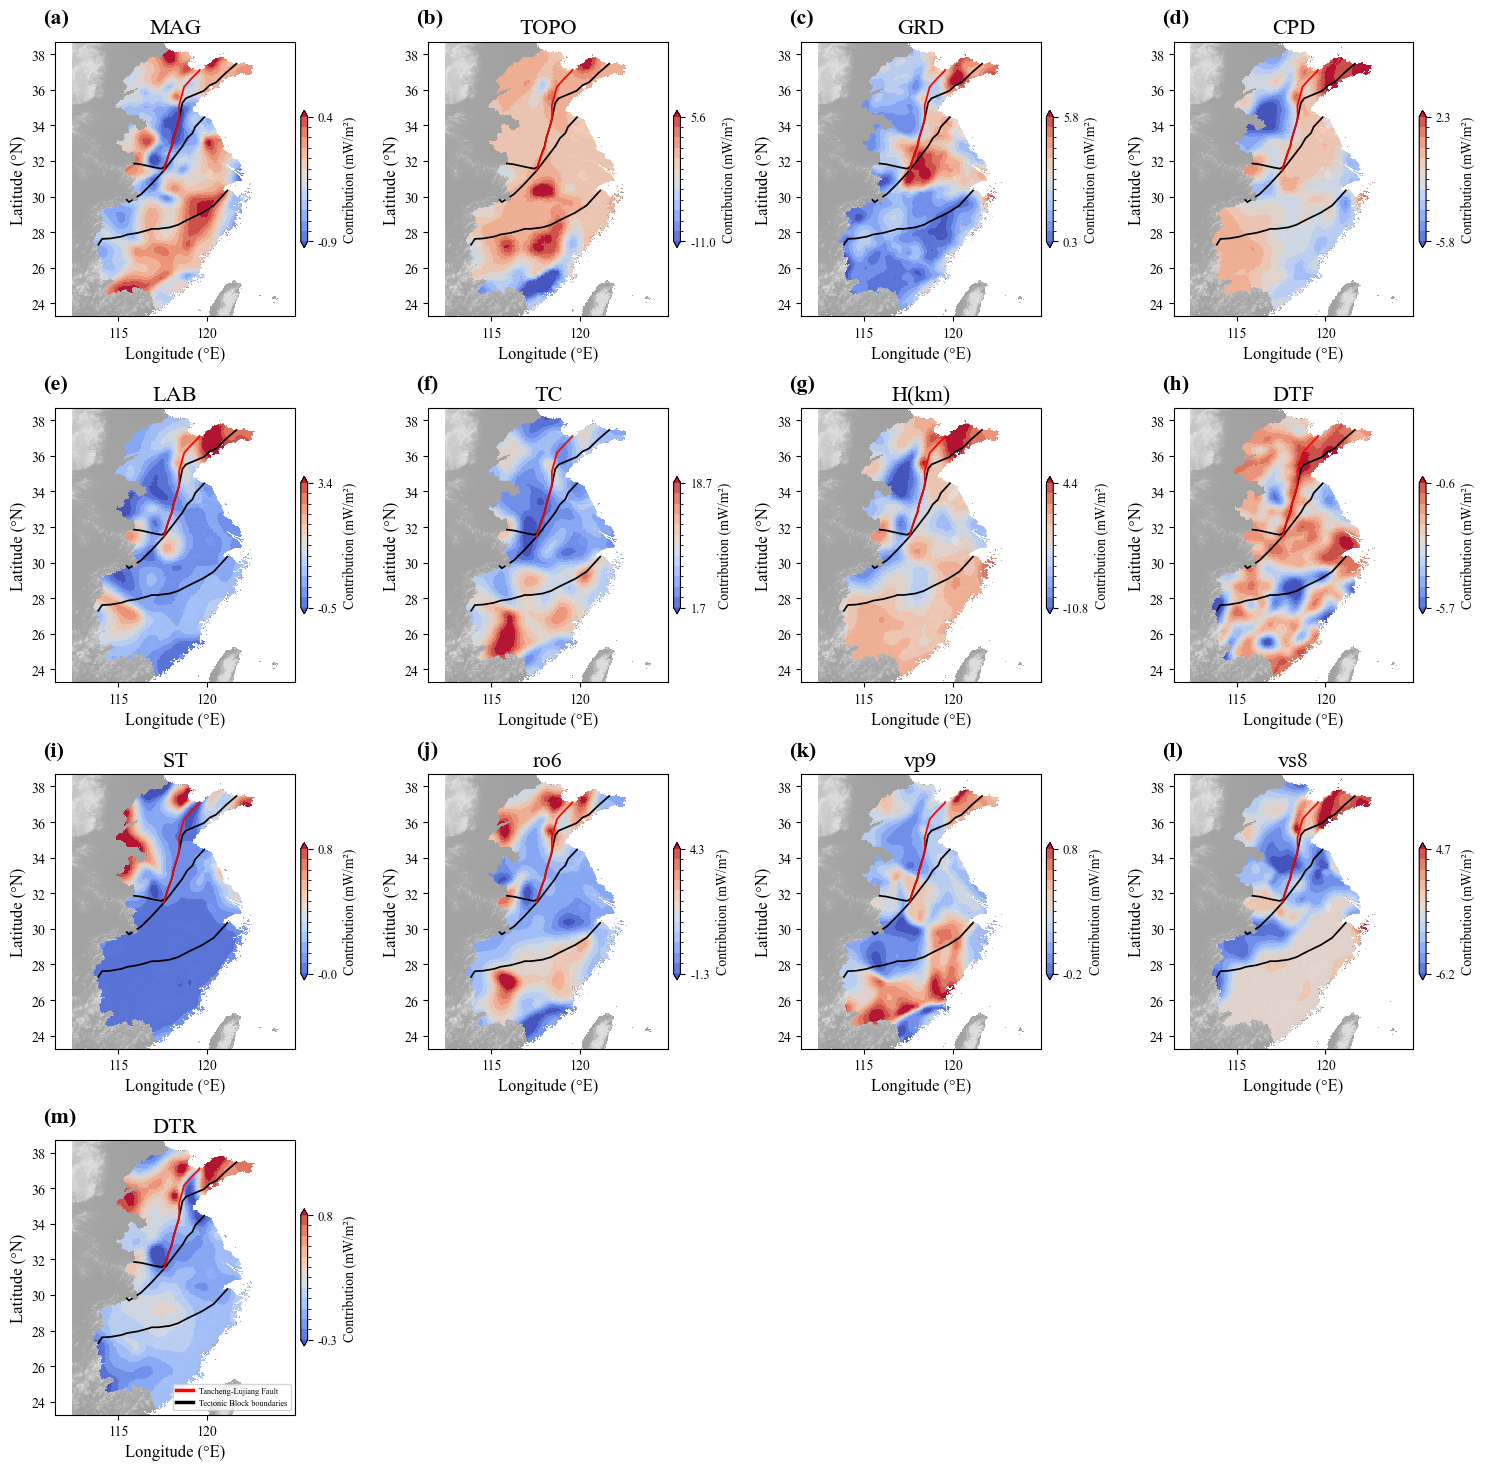

✅ BSRBF_KAN done | Predicted 4131 points


In [6]:
# ---- Load this model's training data and prediction data (uniform mesh) ----
df, X_dist_raw, X_geo_raw, y_raw = load_raw_data(r'c:\KAN-OLS-SHF\output\model\mesh\shf_with_distance_vectors_normal.pkl')
pred_file = r'c:\KAN-OLS-SHF\output\model\mesh\geo_with_distance_vectors_normal.pkl'
pred_df = pd.read_pickle(pred_file)
pred_dist_raw = np.array([np.array(s) if isinstance(s, (list, str)) else s for s in pred_df[DIST_COLS[0]]]).astype(np.float32)
if pred_dist_raw.ndim == 2 and pred_dist_raw.shape[1] == 1:
    pred_dist_raw = np.vstack(pred_dist_raw[:, 0]).astype(np.float32)
pred_geo_raw = pred_df[GEO_COLS].values.astype(np.float32)

# ==================== Cell G: BSRBF_KAN prediction + spatial visualization (uniform mesh + kriging) ====================
model_dir = r'c:\KAN-OLS-SHF\output\train\bsrbf_kan_normal'
print(f"{'='*60}\n🔮 BSRBF_KAN 空间预测与贡献度可视化\n{'='*60}")

# Load model artifacts
pca = joblib.load(os.path.join(model_dir, 'pca.pkl'))
sXd = joblib.load(os.path.join(model_dir, 'scaler_X_dist.pkl'))
sXg = joblib.load(os.path.join(model_dir, 'scaler_X_geo.pkl'))
sy  = joblib.load(os.path.join(model_dir, 'scaler_y.pkl'))
coeffs = np.load(os.path.join(model_dir, 'reg_coefficients.npz'))
beta0_val = float(coeffs['beta0']); beta_vals = np.array(coeffs['beta'], dtype=float).flatten()
cfg = json.load(open(os.path.join(model_dir, 'config.json')))

# Transform prediction data
Xdp = pca.transform(pred_dist_raw); Xds = sXd.transform(Xdp); Xgs = sXg.transform(pred_geo_raw)

# Predict
model = BSRBF_KAN([Xds.shape[1], cfg['n_hidden'], cfg['n_hidden'], n_feat], grid_size=15, spline_order=5).to(device)
model.load_state_dict(torch.load(os.path.join(model_dir, 'best_val_model.pth'), map_location=device)); model.eval()
with torch.no_grad():
    w_pred = model(torch.tensor(Xds, dtype=torch.float32, device=device))
    b0_t = torch.tensor(beta0_val, dtype=torch.float32, device=device)
    b_t  = torch.tensor(beta_vals, dtype=torch.float32, device=device)
    Xg_t = torch.tensor(Xgs, dtype=torch.float32, device=device)
    yp_s = (b0_t + torch.sum(w_pred * b_t * Xg_t, dim=1)).cpu().numpy()
y_pred = sy.inverse_transform(yp_s.reshape(-1,1)).flatten()
print(f"Predicted {len(y_pred)} points | SHF range: [{y_pred.min():.1f}, {y_pred.max():.1f}] mW/m²")

# Contribution decomposition
w_np = w_pred.cpu().numpy(); a = float(sy.inverse_transform(np.array([[1.0]]))[0,0] - sy.inverse_transform(np.array([[0.0]]))[0,0])
contrib_orig = a * (w_np * beta_vals[None,:] * Xgs)
# Contribution on training points (Contribution Summary is drawn using training points)
Xdp_tr = pca.transform(X_dist_raw)
Xds_tr = sXd.transform(Xdp_tr)
Xgs_tr = sXg.transform(X_geo_raw)
with torch.no_grad():
    _wtr = model(torch.tensor(Xds_tr, dtype=torch.float32, device=device))
contrib_tr = a * (_wtr.cpu().numpy() * beta_vals[None, :] * Xgs_tr)
intercept = a * beta0_val + float(sy.inverse_transform(np.array([[0.0]]))[0,0])

# Coordinates & grid
x, y = pred_df['Lon'].values, pred_df['Lat'].values
xmin, xmax, ymin, ymax = get_ext(shapefile, pred_df)
TARGET_GRID = 500
nx = max(1, min(int((xmax - xmin) / 0.02), TARGET_GRID))
ny = max(1, min(int((ymax - ymin) / 0.02), TARGET_GRID))
dx = (xmax - xmin) / nx
dy = (ymax - ymin) / ny
xi = np.arange(xmin, xmax + dx / 2, dx)
yi = np.arange(ymin, ymax + dy / 2, dy)
print(f"Grid: {len(xi)}×{len(yi)} pts, step={dx:.4f}°×{dy:.4f}°")
Xg_g, Yg_g = np.meshgrid(xi, yi)

# ==================== Gray-white terrain basemap (pygmt SRTM15+, optional, as map background) ====================
import os as _os
_env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
_os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
_os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                       _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                       _os.environ.get('PATH', ''))
_tmpdir = r'C:\Users\19023\AppData\Local\Temp'
_os.makedirs(_tmpdir, exist_ok=True)
for _k in ('TMPDIR', 'TEMP', 'TMP'):
    _os.environ[_k] = _tmpdir
import matplotlib.colors as _mcolors

class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # pure white below sea level
        if np.any(land):
            out[land] = self.gray_lo + np.clip(v[land] / self.vland, 0.0, 1.0) * (self.gray_hi - self.gray_lo)
        return out

_gray_norm = GrayTerrainNorm()
import socket as _socket
_proxy_host, _proxy_port = '127.0.0.1', 7890
_sock = _socket.socket(_socket.AF_INET, _socket.SOCK_STREAM)
_sock.settimeout(0.3)
try:
    _sock.connect((_proxy_host, _proxy_port))
    _proxy_ok = True
except OSError:
    _proxy_ok = False
finally:
    _sock.close()
if _proxy_ok:
    _proxy_url = f'http://{_proxy_host}:{_proxy_port}'
    for _key in ('http_proxy', 'https_proxy', 'HTTP_PROXY', 'HTTPS_PROXY', 'GMT_HTTP_PROXY'):
        os.environ[_key] = _proxy_url
else:
    print('[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器')
_t_lon = _t_lat = _t_dem = None
try:
    import pygmt
    _region = [xmin - 1.0, xmax + 1.0, ymin - 0.5, ymax + 0.5]
    _relief = pygmt.datasets.load_earth_relief(resolution='15s', region=_region, registration=None)
    _step = 5
    _t_lon, _t_lat = np.meshgrid(_relief.lon.values[::_step], _relief.lat.values[::_step])
    _t_dem = _relief.values[::_step, ::_step].astype(float)
    print(f"灰白地形底图: {_t_dem.shape}")
except Exception as _e:
    print(f"地形加载失败，跳过地形底图: {_e}")
    _t_lon = _t_lat = _t_dem = None

def _draw_gray_terrain(ax):
    """Draw the gray-white terrain basemap on the current axes (bottom layer, zorder=0)."""
    if _t_dem is not None:
        ax.pcolormesh(_t_lon, _t_lat, _t_dem, cmap='Greys_r', norm=_gray_norm,
                      shading='auto', alpha=0.9, zorder=0)

# ---- Spatial Prediction Map (kriging interpolation) ----
shf_levels = np.arange(40, 105, 5)
norm_shf = BoundaryNorm(shf_levels, ncolors=256, extend='both')

Zg = krige_interp(x, y, y_pred, xi, yi, mask_poly)
# If kriging produces NaN (rare), fill with nearest neighbor first to avoid holes in upsampling
if np.isnan(Zg).any():
    from scipy import ndimage
    _idx = ndimage.distance_transform_edt(np.isnan(Zg), return_distances=False, return_indices=True)
    Zg = Zg[tuple(_idx)]
inside_grid = None
if mask_poly:
    pts = np.column_stack((Xg_g.ravel(), Yg_g.ravel()))
    inside_grid = np.array([mask_poly.contains(Point(px,py)) for px,py in pts]).reshape(Xg_g.shape)

# ---- After kriging, upsample to higher resolution via bilinear interpolation (prediction raster) ----
from scipy.interpolate import RegularGridInterpolator
UPSAMPLE = 4  # subdivision factor: each coarse grid cell is split into UPSAMPLE×UPSAMPLE
# Align fine-grid nodes exactly with coarse-grid nodes (each coarse cell split into UPSAMPLE×UPSAMPLE)
xi_hi = np.linspace(xi[0], xi[-1], (len(xi) - 1) * UPSAMPLE + 1)
yi_hi = np.linspace(yi[0], yi[-1], (len(yi) - 1) * UPSAMPLE + 1)
Xg_hi, Yg_hi = np.meshgrid(xi_hi, yi_hi)
_rgi = RegularGridInterpolator((yi, xi), Zg, method='linear',
                               bounds_error=False, fill_value=np.nan)
Zg_hi = _rgi((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape)
if inside_grid is not None:
    # Upsample the mask bilinearly as well, then clip outside the study area with a 0.5 threshold (avoid slow per-point contains)
    _rgi_mask = RegularGridInterpolator((yi, xi), inside_grid.astype(float),
                                        method='linear', bounds_error=False, fill_value=0.0)
    _in_hi = _rgi_mask((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape) >= 0.5
    Zg_hi[~_in_hi] = np.nan
print(f"  Upsampled prediction grid: {len(xi_hi)}×{len(yi_hi)} pts (bilinear x{UPSAMPLE})")

# Training points that fall inside the study area
train_in = np.array([mask_poly.contains(Point(lon, lat)) for lon, lat in zip(df['Lon'], df['Lat'])]) if mask_poly else np.ones(len(df), dtype=bool)

fig, ax = plt.subplots(figsize=(8, 10))
_draw_gray_terrain(ax)   # gray-white terrain basemap (background)
mesh = ax.pcolormesh(Xg_hi, Yg_hi, Zg_hi, cmap='RdYlBu_r', norm=norm_shf, shading='auto', alpha=0.9, zorder=1)
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('SHF (mW/m²)', fontsize=20)
cbar.ax.tick_params(labelsize=18)
ax.scatter(df.loc[train_in, 'Lon'].values, df.loc[train_in, 'Lat'].values,
           c=y_raw[train_in], cmap='RdYlBu_r', norm=norm_shf, s=15, ec='k', lw=0.5, zorder=5)
ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
plot_bdy(ax, shapefile, 'none', 1.2)
plot_tectonic_bdy(ax)
ax.axis('equal')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.tick_params(labelsize=18)
obs_handle = Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                    markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_handle] + tectonic_legend_handles, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, 200, fontsize=20)
add_north_arrow(ax, 0.02, 20)
plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'spatial_prediction.png'), dpi=800, bbox_inches='tight')
plt.show()
# ---- Contribution Summary ----
from scipy.stats import gaussian_kde, rankdata
from scipy.spatial import cKDTree
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize

ma = np.mean(np.abs(contrib_tr), axis=0)
idx = np.argsort(ma)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for _k, _ax in enumerate(axes):
    _ax.text(-0.05, 1.05, f'({chr(97+_k)})', transform=_ax.transAxes,
             fontsize=16, fontweight='bold', va='bottom', ha='left', clip_on=False)

# ---------- Left: Mean |Contribution| ----------
axes[0].barh(range(n_feat), ma[idx], color='#1f77b4', alpha=0.7, height=0.6)
axes[0].set_yticks(range(n_feat))
axes[0].set_yticklabels([short_names[i] for i in idx])
axes[0].invert_yaxis()
axes[0].tick_params(labelsize=14)
axes[0].grid(axis='x', alpha=0.3)
axes[0].set_xlabel('Mean |Contribution|', fontsize=14)

# ---------- Right: 小提琴（对称）+ 分箱热图内部着色 + 离群点着色 ----------
sorted_cc = contrib_tr[:, idx]
sorted_xg = Xgs_tr[:, idx]

all_cc = sorted_cc.flatten()
max_abs = max(np.abs(all_cc.min()), np.abs(all_cc.max())) * 1.05
cc_min, cc_max = -max_abs, max_abs
x_grid = np.linspace(cc_min, cc_max, 300)

step         = 1.0      # 特征之间间距
violin_half  = 0.42     # 小提琴半高（相对于 step）
cmap         = plt.cm.RdBu_r
norm_c       = Normalize(0.0, 1.0, clip=True)     # 色带刻度 0–1

for j in range(n_feat):
    y0   = (n_feat - 1 - j) * step
    cc_j = sorted_cc[:, j]
    xg_pct_j = (rankdata(sorted_xg[:, j]) - 1) / (len(sorted_xg) - 1)

    # KDE 密度
    try:
        kde = gaussian_kde(cc_j)
    except np.linalg.LinAlgError:
        continue
    dens = kde(x_grid)
    dens = dens / dens.max() * violin_half           # ★ 半高

    # 局部特征值：kNN，窄窗口，颜色随 x 变化明显
    k = max(20, len(cc_j) // 12)
    tree = cKDTree(cc_j.reshape(-1, 1))
    _, inds = tree.query(x_grid.reshape(-1, 1), k=k)
    local_feat = xg_pct_j[inds].mean(axis=1)
    if len(local_feat) > 5:
        local_feat = np.convolve(local_feat, np.ones(5) / 5, mode='same')

    # ★ 逐段构造对称多边形 —— 真正的小提琴形状
    verts, colors_seg = [], []
    for i in range(len(x_grid) - 1):
        h0, h1 = dens[i], dens[i + 1]
        if h0 < 1e-5 and h1 < 1e-5:
            continue
        verts.append([
            (x_grid[i],   y0 - h0),   # 下边
            (x_grid[i+1], y0 - h1),
            (x_grid[i+1], y0 + h1),   # 上边
            (x_grid[i],   y0 + h0),
        ])
        colors_seg.append(local_feat[i])

    if verts:
        coll = PolyCollection(verts, cmap=cmap, norm=norm_c,
                              edgecolors='none', zorder=2 + j * 1e-3)
        coll.set_array(np.array(colors_seg))
        axes[1].add_collection(coll)

    # 小提琴轮廓线
    axes[1].plot(x_grid, y0 + dens, color='0.35', lw=0.5, alpha=0.6,
                 zorder=2.5 + j * 1e-3)
    axes[1].plot(x_grid, y0 - dens, color='0.35', lw=0.5, alpha=0.6,
                 zorder=2.5 + j * 1e-3)

    # ★ 离群点：2.5–97.5 分位之外，直接按特征值着色
    lo, hi = np.percentile(cc_j, [2.5, 97.5])
    out_mask = (cc_j < lo) | (cc_j > hi)
    if out_mask.sum() > 0:
        y_jit = np.random.uniform(-violin_half * 0.35,
                                   violin_half * 0.35, out_mask.sum())
        axes[1].scatter(cc_j[out_mask], y0 + y_jit,
                        c=xg_pct_j[out_mask], cmap=cmap, norm=norm_c,
                        s=10, alpha=0.9, edgecolors='none',
                        zorder=3 + j * 1e-3)

# 装饰
axes[1].axvline(0, color='gray', ls='--', lw=0.8, zorder=0.9)
axes[1].set_yticks([(n_feat - 1 - j) * step for j in range(n_feat)])
axes[1].set_yticklabels([short_names[i] for i in idx])
axes[1].set_xlim(cc_min, cc_max)
axes[1].set_ylim(-0.6, (n_feat - 1) * step + 0.6)
axes[1].tick_params(labelsize=14)
axes[1].grid(axis='x', alpha=0.3)
axes[1].set_xlabel('Contribution', fontsize=14)

sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm_c)
cbar = plt.colorbar(sm, ax=axes[1], shrink=0.6)
cbar.set_label('Feature Value (percentile)', fontsize=14)
cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])   # 0–1 刻度
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'contribution_summary_violin_sym.png'),
            dpi=800, bbox_inches='tight')
plt.show()

# ---- Contribution Maps (grid layout) ----
fig, axes = plt.subplots(5, 4, figsize=(15, 18))
axes = axes.flatten()
for i, fn in enumerate(GEO_COLS):
    Zg_c = krige_interp(x, y, contrib[:, i], xi, yi, mask_poly)
    if inside_grid is not None:
        Zg_c[~inside_grid] = np.nan
    ax = axes[i]
    # Subplot label (top-left outside the axes)
    ax.text(-0.05, 1.05, f'({chr(97+i)})', transform=ax.transAxes, fontsize=16, fontweight='bold', va='bottom', ha='left', clip_on=False)
    valid_c = Zg_c[~np.isnan(Zg_c)]
    if len(valid_c) > 0:
        vmin_c = np.percentile(valid_c, 2)
        vmax_c = np.percentile(valid_c, 98)
        if vmax_c - vmin_c < 1e-12:
            vmin_c, vmax_c = -1, 1
        levels_c = np.linspace(vmin_c, vmax_c, 13)
        norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    else:
        vmin_c, vmax_c = -1, 1
        levels_c = np.linspace(vmin_c, vmax_c, 13)
        norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    _draw_gray_terrain(ax)   # gray-white terrain basemap (background)
    mesh_c = ax.pcolormesh(Xg_g, Yg_g, Zg_c, cmap='coolwarm', norm=norm_c, shading='auto', alpha=0.9, zorder=1)
    cb = plt.colorbar(mesh_c, ax=ax, shrink=0.5, pad=0.02)
    cb.set_label('Contribution (mW/m²)', fontsize=10)
    cb.set_ticks([vmin_c, vmax_c])
    cb.set_ticklabels([f'{vmin_c:.1f}', f'{vmax_c:.1f}'])
    cb.ax.tick_params(labelsize=9)
    plot_bdy(ax, shapefile, 'none', 1.0)
    plot_tectonic_bdy(ax, scale=0.5)
    ax.axis('equal')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(short_names[i], fontsize=16)
    ax.set_xlabel('Longitude (°E)', fontsize=12)
    ax.set_ylabel('Latitude (°N)', fontsize=12)
    ax.tick_params(labelsize=10)

# Hide empty subplots beyond the feature count, and put the legend on the last visible subplot
for j in range(n_feat, len(axes)):
    axes[j].set_visible(False)
axes[n_feat - 1].legend(handles=tectonic_legend_handles, loc='lower right', fontsize=6, framealpha=0.8)
plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'contribution_maps.png'), dpi=800, bbox_inches='tight')
plt.show()

print(f'✅ BSRBF_KAN done | Predicted {len(y_pred)} points')


数据列: ['数据编号', 'Lon', 'Lat', 'SHF__mW_m2_', 'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU', 'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'crsthk', 'sedthk-m', 'bd6', 'bd7', 'bd8', 'bd9', 'ro6', 'ro7', 'ro8', 'ro9', 'vp6', 'vp7', 'vp8', 'vp9', 'vs6', 'vs7', 'vs8', 'vs9', 'H(km)', 'DTF', 'DTR', 'distance_vector_to_grids']
🔮 MLP 空间预测与贡献度可视化
Predicted 4131 points | SHF range: [21.3, 143.6] mW/m²
Grid: 482×501 pts, step=0.0200°×0.0308°
[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器
灰白地形底图: (789, 559)
  Upsampled prediction grid: 1925×2001 pts (bilinear x4)


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


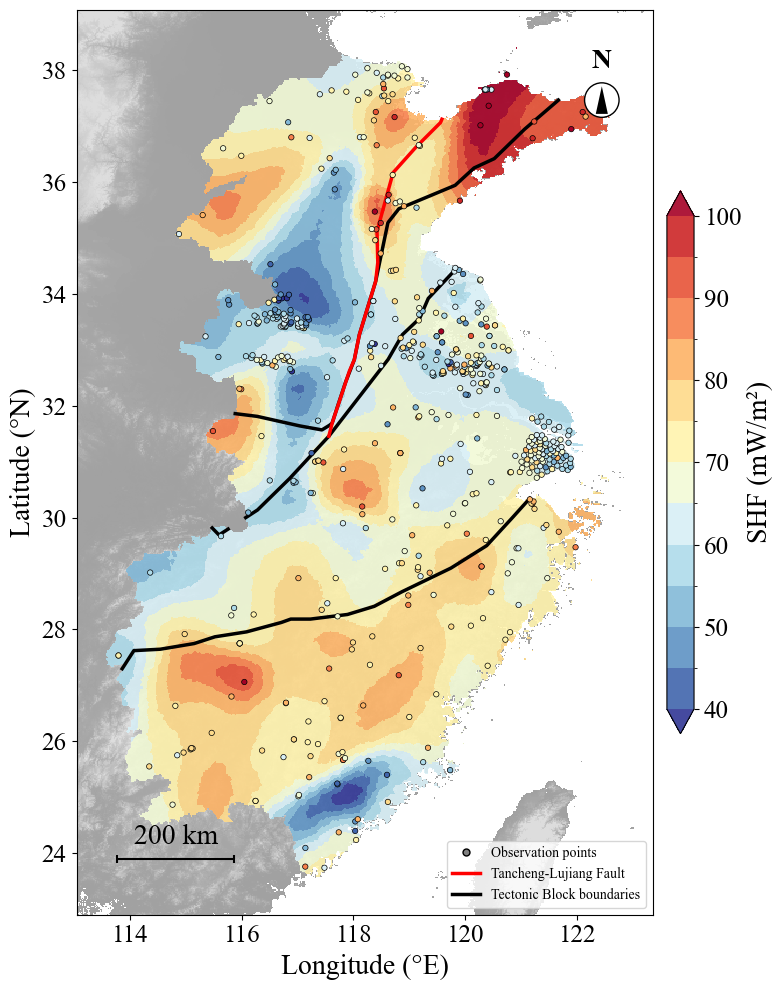

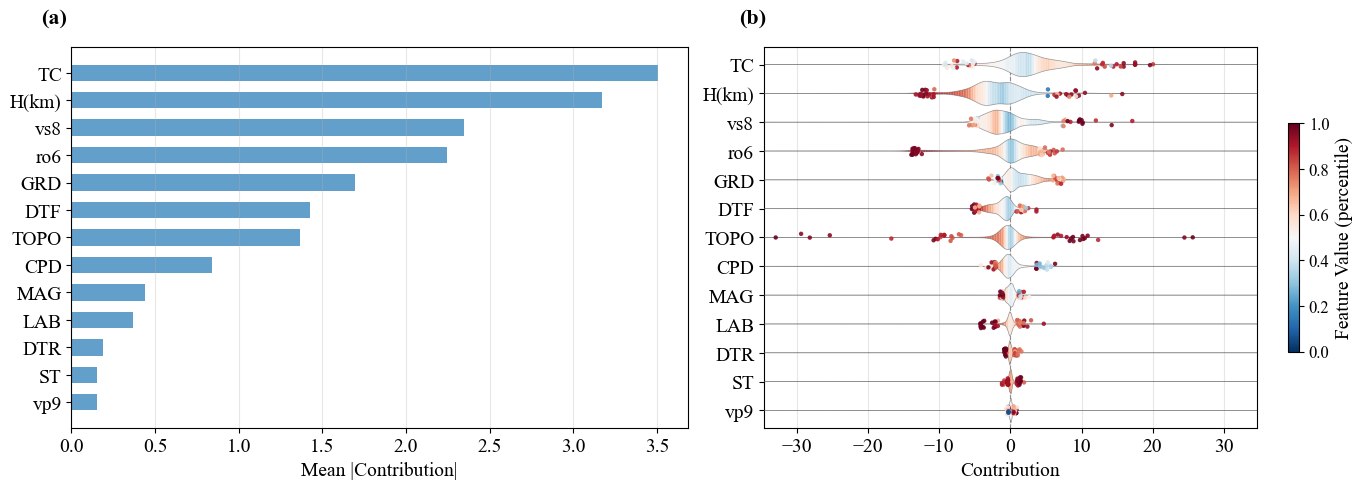

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x

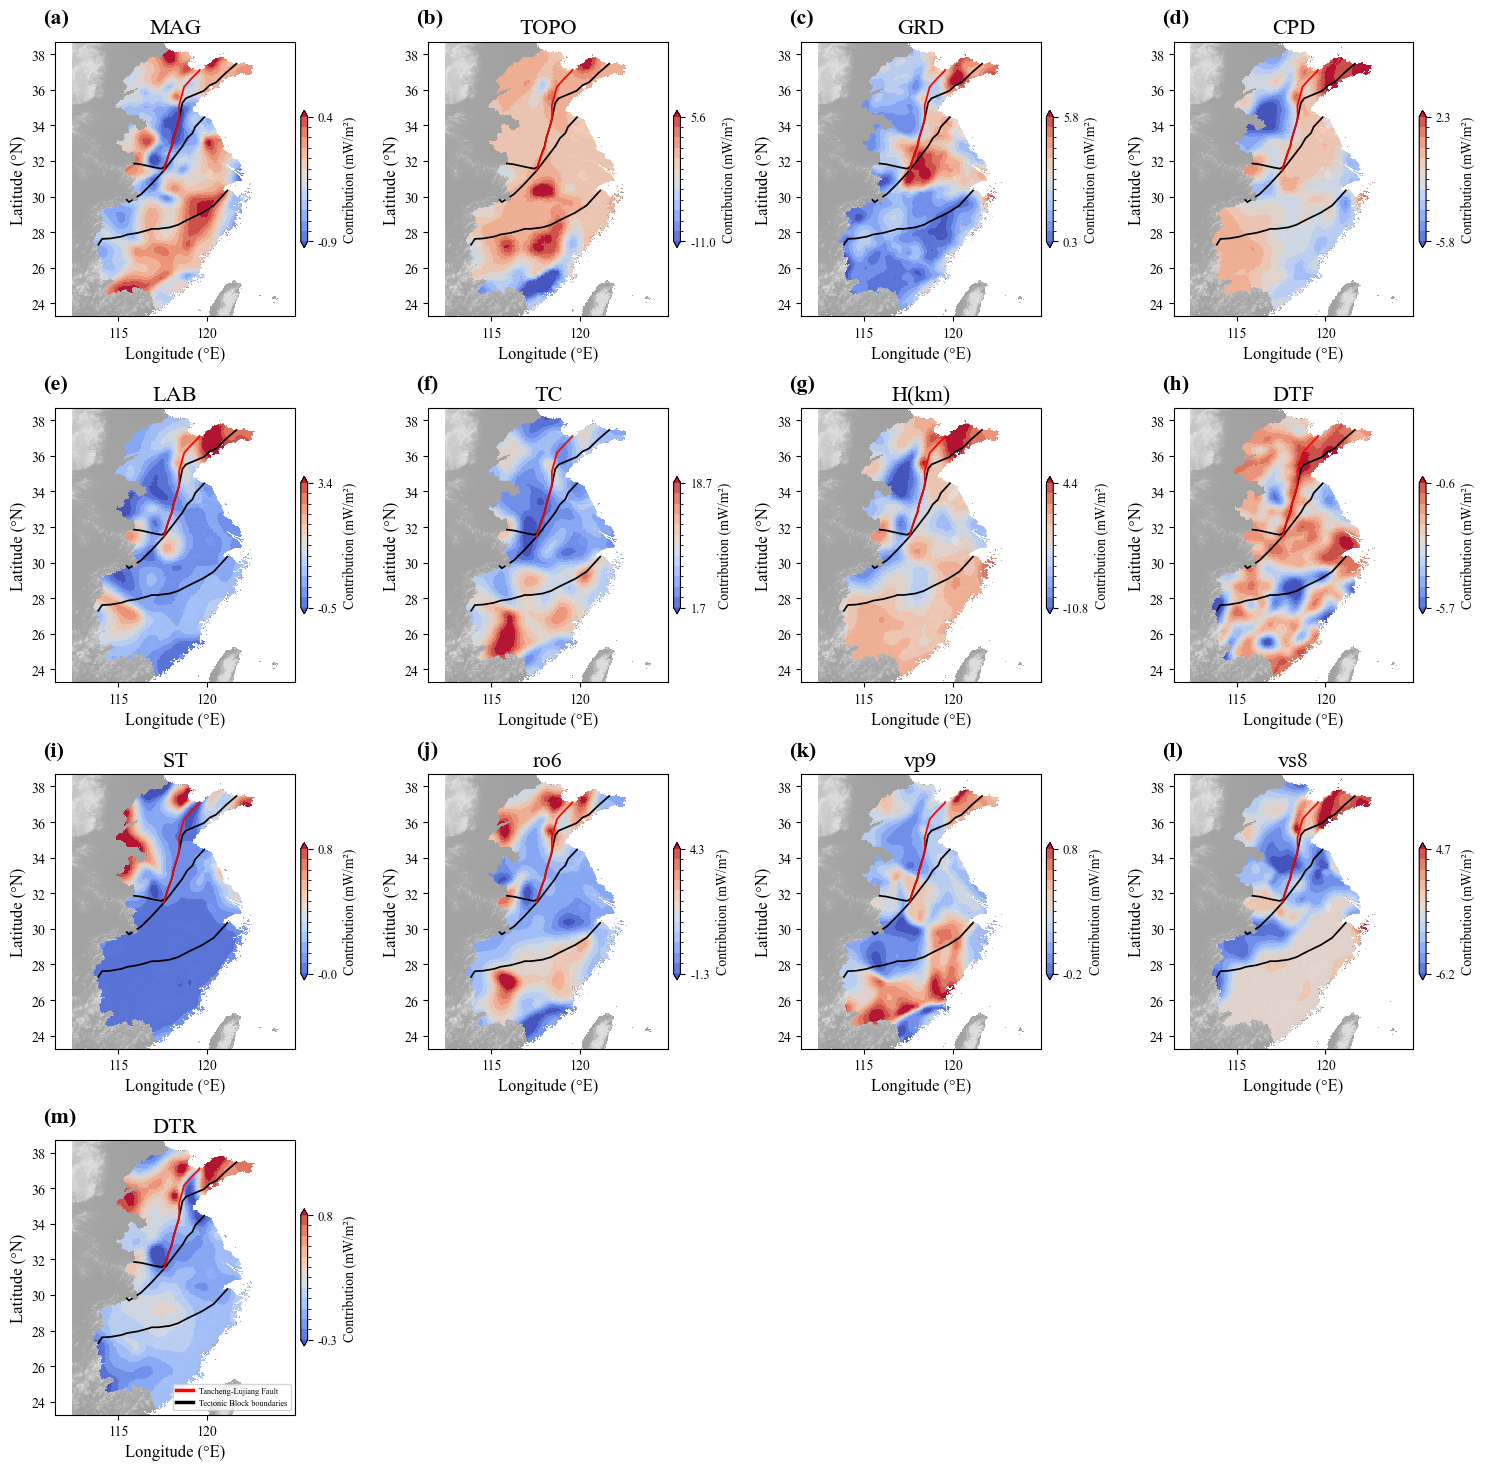

✅ MLP done | Predicted 4131 points


In [7]:
# ---- Load this model's training data and prediction data (uniform mesh) ----
df, X_dist_raw, X_geo_raw, y_raw = load_raw_data(r'c:\KAN-OLS-SHF\output\model\mesh\shf_with_distance_vectors_normal.pkl')
pred_file = r'c:\KAN-OLS-SHF\output\model\mesh\geo_with_distance_vectors_normal.pkl'
pred_df = pd.read_pickle(pred_file)
pred_dist_raw = np.array([np.array(s) if isinstance(s, (list, str)) else s for s in pred_df[DIST_COLS[0]]]).astype(np.float32)
if pred_dist_raw.ndim == 2 and pred_dist_raw.shape[1] == 1:
    pred_dist_raw = np.vstack(pred_dist_raw[:, 0]).astype(np.float32)
pred_geo_raw = pred_df[GEO_COLS].values.astype(np.float32)

# ==================== Cell H: MLP prediction + spatial visualization (uniform mesh + kriging) ====================
model_dir = r'c:\KAN-OLS-SHF\output\train\mlp_normal'
print(f"{'='*60}\n🔮 MLP 空间预测与贡献度可视化\n{'='*60}")

# Load model artifacts
pca = joblib.load(os.path.join(model_dir, 'pca.pkl'))
sXd = joblib.load(os.path.join(model_dir, 'scaler_X_dist.pkl'))
sXg = joblib.load(os.path.join(model_dir, 'scaler_X_geo.pkl'))
sy  = joblib.load(os.path.join(model_dir, 'scaler_y.pkl'))
coeffs = np.load(os.path.join(model_dir, 'reg_coefficients.npz'))
beta0_val = float(coeffs['beta0']); beta_vals = np.array(coeffs['beta'], dtype=float).flatten()
cfg = json.load(open(os.path.join(model_dir, 'config.json')))

# Transform prediction data
Xdp = pca.transform(pred_dist_raw); Xds = sXd.transform(Xdp); Xgs = sXg.transform(pred_geo_raw)

# Predict
model = MLP([Xds.shape[1], cfg['n_hidden'], cfg['n_hidden'], n_feat]).to(device)
model.load_state_dict(torch.load(os.path.join(model_dir, 'best_val_model.pth'), map_location=device)); model.eval()
with torch.no_grad():
    w_pred = model(torch.tensor(Xds, dtype=torch.float32, device=device))
    b0_t = torch.tensor(beta0_val, dtype=torch.float32, device=device)
    b_t  = torch.tensor(beta_vals, dtype=torch.float32, device=device)
    Xg_t = torch.tensor(Xgs, dtype=torch.float32, device=device)
    yp_s = (b0_t + torch.sum(w_pred * b_t * Xg_t, dim=1)).cpu().numpy()
y_pred = sy.inverse_transform(yp_s.reshape(-1,1)).flatten()
print(f"Predicted {len(y_pred)} points | SHF range: [{y_pred.min():.1f}, {y_pred.max():.1f}] mW/m²")

# Contribution decomposition
w_np = w_pred.cpu().numpy(); a = float(sy.inverse_transform(np.array([[1.0]]))[0,0] - sy.inverse_transform(np.array([[0.0]]))[0,0])
contrib_orig = a * (w_np * beta_vals[None,:] * Xgs)
# Contribution on training points (Contribution Summary is drawn using training points)
Xdp_tr = pca.transform(X_dist_raw)
Xds_tr = sXd.transform(Xdp_tr)
Xgs_tr = sXg.transform(X_geo_raw)
with torch.no_grad():
    _wtr = model(torch.tensor(Xds_tr, dtype=torch.float32, device=device))
contrib_tr = a * (_wtr.cpu().numpy() * beta_vals[None, :] * Xgs_tr)
intercept = a * beta0_val + float(sy.inverse_transform(np.array([[0.0]]))[0,0])

# Coordinates & grid
x, y = pred_df['Lon'].values, pred_df['Lat'].values
xmin, xmax, ymin, ymax = get_ext(shapefile, pred_df)
TARGET_GRID = 500
nx = max(1, min(int((xmax - xmin) / 0.02), TARGET_GRID))
ny = max(1, min(int((ymax - ymin) / 0.02), TARGET_GRID))
dx = (xmax - xmin) / nx
dy = (ymax - ymin) / ny
xi = np.arange(xmin, xmax + dx / 2, dx)
yi = np.arange(ymin, ymax + dy / 2, dy)
print(f"Grid: {len(xi)}×{len(yi)} pts, step={dx:.4f}°×{dy:.4f}°")
Xg_g, Yg_g = np.meshgrid(xi, yi)

# ==================== Gray-white terrain basemap (pygmt SRTM15+, optional, as map background) ====================
import os as _os
_env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
_os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
_os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                       _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                       _os.environ.get('PATH', ''))
_tmpdir = r'C:\Users\19023\AppData\Local\Temp'
_os.makedirs(_tmpdir, exist_ok=True)
for _k in ('TMPDIR', 'TEMP', 'TMP'):
    _os.environ[_k] = _tmpdir
import matplotlib.colors as _mcolors

class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # pure white below sea level
        if np.any(land):
            out[land] = self.gray_lo + np.clip(v[land] / self.vland, 0.0, 1.0) * (self.gray_hi - self.gray_lo)
        return out

_gray_norm = GrayTerrainNorm()
import socket as _socket
_proxy_host, _proxy_port = '127.0.0.1', 7890
_sock = _socket.socket(_socket.AF_INET, _socket.SOCK_STREAM)
_sock.settimeout(0.3)
try:
    _sock.connect((_proxy_host, _proxy_port))
    _proxy_ok = True
except OSError:
    _proxy_ok = False
finally:
    _sock.close()
if _proxy_ok:
    _proxy_url = f'http://{_proxy_host}:{_proxy_port}'
    for _key in ('http_proxy', 'https_proxy', 'HTTP_PROXY', 'HTTPS_PROXY', 'GMT_HTTP_PROXY'):
        os.environ[_key] = _proxy_url
else:
    print('[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器')
_t_lon = _t_lat = _t_dem = None
try:
    import pygmt
    _region = [xmin - 1.0, xmax + 1.0, ymin - 0.5, ymax + 0.5]
    _relief = pygmt.datasets.load_earth_relief(resolution='15s', region=_region, registration=None)
    _step = 5
    _t_lon, _t_lat = np.meshgrid(_relief.lon.values[::_step], _relief.lat.values[::_step])
    _t_dem = _relief.values[::_step, ::_step].astype(float)
    print(f"灰白地形底图: {_t_dem.shape}")
except Exception as _e:
    print(f"地形加载失败，跳过地形底图: {_e}")
    _t_lon = _t_lat = _t_dem = None

def _draw_gray_terrain(ax):
    """Draw the gray-white terrain basemap on the current axes (bottom layer, zorder=0)."""
    if _t_dem is not None:
        ax.pcolormesh(_t_lon, _t_lat, _t_dem, cmap='Greys_r', norm=_gray_norm,
                      shading='auto', alpha=0.9, zorder=0)

# ---- Spatial Prediction Map (kriging interpolation) ----
shf_levels = np.arange(40, 105, 5)
norm_shf = BoundaryNorm(shf_levels, ncolors=256, extend='both')

Zg = krige_interp(x, y, y_pred, xi, yi, mask_poly)
# If kriging produces NaN (rare), fill with nearest neighbor first to avoid holes in upsampling
if np.isnan(Zg).any():
    from scipy import ndimage
    _idx = ndimage.distance_transform_edt(np.isnan(Zg), return_distances=False, return_indices=True)
    Zg = Zg[tuple(_idx)]
inside_grid = None
if mask_poly:
    pts = np.column_stack((Xg_g.ravel(), Yg_g.ravel()))
    inside_grid = np.array([mask_poly.contains(Point(px,py)) for px,py in pts]).reshape(Xg_g.shape)

# ---- After kriging, upsample to higher resolution via bilinear interpolation (prediction raster) ----
from scipy.interpolate import RegularGridInterpolator
UPSAMPLE = 4  # subdivision factor: each coarse grid cell is split into UPSAMPLE×UPSAMPLE
# Align fine-grid nodes exactly with coarse-grid nodes (each coarse cell split into UPSAMPLE×UPSAMPLE)
xi_hi = np.linspace(xi[0], xi[-1], (len(xi) - 1) * UPSAMPLE + 1)
yi_hi = np.linspace(yi[0], yi[-1], (len(yi) - 1) * UPSAMPLE + 1)
Xg_hi, Yg_hi = np.meshgrid(xi_hi, yi_hi)
_rgi = RegularGridInterpolator((yi, xi), Zg, method='linear',
                               bounds_error=False, fill_value=np.nan)
Zg_hi = _rgi((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape)
if inside_grid is not None:
    # Upsample the mask bilinearly as well, then clip outside the study area with a 0.5 threshold (avoid slow per-point contains)
    _rgi_mask = RegularGridInterpolator((yi, xi), inside_grid.astype(float),
                                        method='linear', bounds_error=False, fill_value=0.0)
    _in_hi = _rgi_mask((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape) >= 0.5
    Zg_hi[~_in_hi] = np.nan
print(f"  Upsampled prediction grid: {len(xi_hi)}×{len(yi_hi)} pts (bilinear x{UPSAMPLE})")

# Training points that fall inside the study area
train_in = np.array([mask_poly.contains(Point(lon, lat)) for lon, lat in zip(df['Lon'], df['Lat'])]) if mask_poly else np.ones(len(df), dtype=bool)

fig, ax = plt.subplots(figsize=(8, 10))
_draw_gray_terrain(ax)   # gray-white terrain basemap (background)
mesh = ax.pcolormesh(Xg_hi, Yg_hi, Zg_hi, cmap='RdYlBu_r', norm=norm_shf, shading='auto', alpha=0.9, zorder=1)
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('SHF (mW/m²)', fontsize=20)
cbar.ax.tick_params(labelsize=18)
ax.scatter(df.loc[train_in, 'Lon'].values, df.loc[train_in, 'Lat'].values,
           c=y_raw[train_in], cmap='RdYlBu_r', norm=norm_shf, s=15, ec='k', lw=0.5, zorder=5)
ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
plot_bdy(ax, shapefile, 'none', 1.2)
plot_tectonic_bdy(ax)
ax.axis('equal')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.tick_params(labelsize=18)
obs_handle = Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                    markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_handle] + tectonic_legend_handles, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, 200, fontsize=20)
add_north_arrow(ax, 0.02, 20)
plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'spatial_prediction.png'), dpi=800, bbox_inches='tight')
plt.show()
# ---- Contribution Summary ----
from scipy.stats import gaussian_kde, rankdata
from scipy.spatial import cKDTree
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize

ma = np.mean(np.abs(contrib_tr), axis=0)
idx = np.argsort(ma)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for _k, _ax in enumerate(axes):
    _ax.text(-0.05, 1.05, f'({chr(97+_k)})', transform=_ax.transAxes,
             fontsize=16, fontweight='bold', va='bottom', ha='left', clip_on=False)

# ---------- Left: Mean |Contribution| ----------
axes[0].barh(range(n_feat), ma[idx], color='#1f77b4', alpha=0.7, height=0.6)
axes[0].set_yticks(range(n_feat))
axes[0].set_yticklabels([short_names[i] for i in idx])
axes[0].invert_yaxis()
axes[0].tick_params(labelsize=14)
axes[0].grid(axis='x', alpha=0.3)
axes[0].set_xlabel('Mean |Contribution|', fontsize=14)

# ---------- Right: 小提琴（对称）+ 分箱热图内部着色 + 离群点着色 ----------
sorted_cc = contrib_tr[:, idx]
sorted_xg = Xgs_tr[:, idx]

all_cc = sorted_cc.flatten()
max_abs = max(np.abs(all_cc.min()), np.abs(all_cc.max())) * 1.05
cc_min, cc_max = -max_abs, max_abs
x_grid = np.linspace(cc_min, cc_max, 300)

step         = 1.0      # 特征之间间距
violin_half  = 0.42     # 小提琴半高（相对于 step）
cmap         = plt.cm.RdBu_r
norm_c       = Normalize(0.0, 1.0, clip=True)     # 色带刻度 0–1

for j in range(n_feat):
    y0   = (n_feat - 1 - j) * step
    cc_j = sorted_cc[:, j]
    xg_pct_j = (rankdata(sorted_xg[:, j]) - 1) / (len(sorted_xg) - 1)

    # KDE 密度
    try:
        kde = gaussian_kde(cc_j)
    except np.linalg.LinAlgError:
        continue
    dens = kde(x_grid)
    dens = dens / dens.max() * violin_half           # ★ 半高

    # 局部特征值：kNN，窄窗口，颜色随 x 变化明显
    k = max(20, len(cc_j) // 12)
    tree = cKDTree(cc_j.reshape(-1, 1))
    _, inds = tree.query(x_grid.reshape(-1, 1), k=k)
    local_feat = xg_pct_j[inds].mean(axis=1)
    if len(local_feat) > 5:
        local_feat = np.convolve(local_feat, np.ones(5) / 5, mode='same')

    # ★ 逐段构造对称多边形 —— 真正的小提琴形状
    verts, colors_seg = [], []
    for i in range(len(x_grid) - 1):
        h0, h1 = dens[i], dens[i + 1]
        if h0 < 1e-5 and h1 < 1e-5:
            continue
        verts.append([
            (x_grid[i],   y0 - h0),   # 下边
            (x_grid[i+1], y0 - h1),
            (x_grid[i+1], y0 + h1),   # 上边
            (x_grid[i],   y0 + h0),
        ])
        colors_seg.append(local_feat[i])

    if verts:
        coll = PolyCollection(verts, cmap=cmap, norm=norm_c,
                              edgecolors='none', zorder=2 + j * 1e-3)
        coll.set_array(np.array(colors_seg))
        axes[1].add_collection(coll)

    # 小提琴轮廓线
    axes[1].plot(x_grid, y0 + dens, color='0.35', lw=0.5, alpha=0.6,
                 zorder=2.5 + j * 1e-3)
    axes[1].plot(x_grid, y0 - dens, color='0.35', lw=0.5, alpha=0.6,
                 zorder=2.5 + j * 1e-3)

    # ★ 离群点：2.5–97.5 分位之外，直接按特征值着色
    lo, hi = np.percentile(cc_j, [2.5, 97.5])
    out_mask = (cc_j < lo) | (cc_j > hi)
    if out_mask.sum() > 0:
        y_jit = np.random.uniform(-violin_half * 0.35,
                                   violin_half * 0.35, out_mask.sum())
        axes[1].scatter(cc_j[out_mask], y0 + y_jit,
                        c=xg_pct_j[out_mask], cmap=cmap, norm=norm_c,
                        s=10, alpha=0.9, edgecolors='none',
                        zorder=3 + j * 1e-3)

# 装饰
axes[1].axvline(0, color='gray', ls='--', lw=0.8, zorder=0.9)
axes[1].set_yticks([(n_feat - 1 - j) * step for j in range(n_feat)])
axes[1].set_yticklabels([short_names[i] for i in idx])
axes[1].set_xlim(cc_min, cc_max)
axes[1].set_ylim(-0.6, (n_feat - 1) * step + 0.6)
axes[1].tick_params(labelsize=14)
axes[1].grid(axis='x', alpha=0.3)
axes[1].set_xlabel('Contribution', fontsize=14)

sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm_c)
cbar = plt.colorbar(sm, ax=axes[1], shrink=0.6)
cbar.set_label('Feature Value (percentile)', fontsize=14)
cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])   # 0–1 刻度
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'contribution_summary_violin_sym.png'),
            dpi=800, bbox_inches='tight')
plt.show()

# ---- Contribution Maps (grid layout) ----
fig, axes = plt.subplots(5, 4, figsize=(15, 18))
axes = axes.flatten()
for i, fn in enumerate(GEO_COLS):
    Zg_c = krige_interp(x, y, contrib[:, i], xi, yi, mask_poly)
    if inside_grid is not None:
        Zg_c[~inside_grid] = np.nan
    ax = axes[i]
    # Subplot label (top-left outside the axes)
    ax.text(-0.05, 1.05, f'({chr(97+i)})', transform=ax.transAxes, fontsize=16, fontweight='bold', va='bottom', ha='left', clip_on=False)
    valid_c = Zg_c[~np.isnan(Zg_c)]
    if len(valid_c) > 0:
        vmin_c = np.percentile(valid_c, 2)
        vmax_c = np.percentile(valid_c, 98)
        if vmax_c - vmin_c < 1e-12:
            vmin_c, vmax_c = -1, 1
        levels_c = np.linspace(vmin_c, vmax_c, 13)
        norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    else:
        vmin_c, vmax_c = -1, 1
        levels_c = np.linspace(vmin_c, vmax_c, 13)
        norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    _draw_gray_terrain(ax)   # gray-white terrain basemap (background)
    mesh_c = ax.pcolormesh(Xg_g, Yg_g, Zg_c, cmap='coolwarm', norm=norm_c, shading='auto', alpha=0.9, zorder=1)
    cb = plt.colorbar(mesh_c, ax=ax, shrink=0.5, pad=0.02)
    cb.set_label('Contribution (mW/m²)', fontsize=10)
    cb.set_ticks([vmin_c, vmax_c])
    cb.set_ticklabels([f'{vmin_c:.1f}', f'{vmax_c:.1f}'])
    cb.ax.tick_params(labelsize=9)
    plot_bdy(ax, shapefile, 'none', 1.0)
    plot_tectonic_bdy(ax, scale=0.5)
    ax.axis('equal')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(short_names[i], fontsize=16)
    ax.set_xlabel('Longitude (°E)', fontsize=12)
    ax.set_ylabel('Latitude (°N)', fontsize=12)
    ax.tick_params(labelsize=10)

# Hide empty subplots beyond the feature count, and put the legend on the last visible subplot
for j in range(n_feat, len(axes)):
    axes[j].set_visible(False)
axes[n_feat - 1].legend(handles=tectonic_legend_handles, loc='lower right', fontsize=6, framealpha=0.8)
plt.tight_layout()
plt.savefig(os.path.join(model_dir, 'contribution_maps.png'), dpi=800, bbox_inches='tight')
plt.show()

print(f'✅ MLP done | Predicted {len(y_pred)} points')
